# TCGA BRCA Preprocessing Notebook
**This notebook performs the full preprocessing pipeline for the TCGA Breast Invasive Carcinoma (BRCA) project.**

**It reads the four source files, standardizes missing values, cleans each dataset, aggregates treatment tables to the patient level, merges everything into one master dataset, and then creates the final analysis-ready table plus a machine-learning-friendly encoded version.**

**The goal is to preserve clinically meaningful information while producing a clean, consistent, one-row-per-patient dataset that is ready for survival analysis and downstream modeling.**

In [1]:
# %% [1] Importing libraries and setting up the notebook environment
from pathlib import Path
import warnings

import numpy as np
import pandas as pd

from IPython.display import display

warnings.filterwarnings("ignore")

# Showing all columns in displayed tables makes notebook output easier to inspect.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)
pd.set_option("display.max_colwidth", 100)

# Source files
MAIN_PATH = Path(r"C:\Users\El-Wattaneya\Downloads\Main BRCA Clinical Patient Data.csv")
RADIATION_PATH = Path(r"C:\Users\El-Wattaneya\Downloads\BRCA Radiation Data.csv")
DRUG_PATH = Path(r"C:\Users\El-Wattaneya\Downloads\BRCA Drug Data.csv")
FOLLOWUP_PATH = Path(r"C:\Users\El-Wattaneya\Downloads\BRCA Follow-up Data.csv")

print("Setting up the workspace")
print(f"Main clinical file:   {MAIN_PATH}")
print(f"Radiation file:       {RADIATION_PATH}")
print(f"Drug file:            {DRUG_PATH}")
print(f"Follow-up file:       {FOLLOWUP_PATH}")

Setting up the workspace
Main clinical file:   C:\Users\El-Wattaneya\Downloads\Main BRCA Clinical Patient Data.csv
Radiation file:       C:\Users\El-Wattaneya\Downloads\BRCA Radiation Data.csv
Drug file:            C:\Users\El-Wattaneya\Downloads\BRCA Drug Data.csv
Follow-up file:       C:\Users\El-Wattaneya\Downloads\BRCA Follow-up Data.csv


**Helper functions**

**The following helper functions standardize missing values, convert text and numeric fields into consistent formats, and simplify repeated operations such as selecting the latest record per patient or collapsing detailed stage labels.**

**These helpers are designed to keep the cleaning steps readable and reusable across the different source files.**

In [3]:
# %% [2] Defining helper functions

def standardize_missing_values(df: pd.DataFrame) -> pd.DataFrame:
    """
    Standardize missing values across text fields and trim unnecessary whitespace.

    This function:
    - strips whitespace from column names
    - trims whitespace from string values
    - replaces common missing-value placeholders such as "NA", "N/A", "null", "None", and blank strings
      with actual pandas missing values (pd.NA)
    """
    df = df.copy()
    df.columns = [c.strip() for c in df.columns]

    object_cols = df.select_dtypes(include=["object", "string"]).columns
    for col in object_cols:
        df[col] = df[col].astype("string").str.strip()
        df[col] = df[col].replace(
            to_replace=[
                r"(?i)^\s*$",
                r"(?i)^\s*na\s*$",
                r"(?i)^\s*n/a\s*$",
                r"(?i)^\s*null\s*$",
                r"(?i)^\s*none\s*$",
                r"(?i)^\s*nan\s*$",
                r"(?i)^\s*not available\s*$",
                r"(?i)^\s*not applicable\s*$",
                r"(?i)^\s*\[not available\]\s*$",
                r"(?i)^\s*\[not applicable\]\s*$",
            ],
            value=pd.NA,
            regex=True,
        )
    return df


def coerce_numeric_columns(df: pd.DataFrame, columns: list[str], allow_negative: bool = True) -> pd.DataFrame:
    """
    Convert selected columns to numeric.

    Any non-numeric values are coerced to NaN. If allow_negative is False,
    negative values are also treated as missing because they are impossible for duration/count variables.
    """
    df = df.copy()
    for col in columns:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
            if not allow_negative:
                df.loc[df[col] < 0, col] = np.nan
    return df


def standardize_binary_series(series: pd.Series) -> pd.Series:
    """
    Standardize yes/no-like values into a consistent representation.

    Common positive values are converted to "Yes" and common negative values to "No".
    This is especially useful for treatment indicators and biomarker fields.
    """
    s = series.astype("string").str.strip().str.lower()

    yes_values = {
        "yes", "y", "true", "1", "positive", "present", "received", "treated", "on", "ongoing"
    }
    no_values = {
        "no", "n", "false", "0", "negative", "absent", "not received", "off", "completed"
    }

    s = s.replace({v: "Yes" for v in yes_values})
    s = s.replace({v: "No" for v in no_values})
    s = s.replace({"<na>": pd.NA, "nan": pd.NA})
    return s


def standardize_vital_status(series: pd.Series) -> pd.Series:
    """
    Standardize survival status values into the two expected categories:
    - Alive
    - Dead

    Any other label is treated as missing.
    """
    s = series.astype("string").str.strip().str.lower()
    s = s.replace({
        "alive": "Alive",
        "dead": "Dead",
    })
    s = s.where(s.isin(["Alive", "Dead"]), pd.NA)
    return s


def simplify_stage(value):
    """
    Collapse detailed AJCC stage labels into broader stage groups.

    The output categories are:
    - Stage 0
    - Stage I
    - Stage II
    - Stage III
    - Stage IV

    Anything that cannot be interpreted is returned as missing.
    """
    if pd.isna(value):
        return pd.NA

    s = str(value).upper().strip()
    s = s.replace("STAGE", "").strip()

    if s.startswith("0"):
        return "Stage 0"
    if "IV" in s:
        return "Stage IV"
    if "III" in s:
        return "Stage III"
    if "II" in s:
        return "Stage II"
    if s.startswith("I"):
        return "Stage I"
    return pd.NA


def mode_or_nan(series: pd.Series):
    """
    Return the most common non-missing value.
    If the series is empty after removing missing values, return pd.NA.
    """
    s = series.dropna()
    if s.empty:
        return pd.NA
    m = s.mode()
    if len(m) == 0:
        return s.iloc[0]
    return m.iloc[0]


def latest_record_per_patient(df: pd.DataFrame, patient_col: str, date_col: str) -> pd.DataFrame:
    """
    Keep the latest record per patient using a date column.

    This is especially useful for the follow-up table, which may contain multiple entries per patient.
    """
    df = df.copy()
    sort_cols = [patient_col]

    if date_col in df.columns:
        sort_cols.append(date_col)

    # These are extra tie-breakers if available
    extra_sort_cols = [
        c for c in ["days_to_last_followup", "days_to_death", "form_completion_date"]
        if c in df.columns and c not in sort_cols
    ]
    sort_cols.extend(extra_sort_cols)

    df = df.sort_values(sort_cols, ascending=True, na_position="first")
    latest = df.groupby(patient_col, as_index=False).tail(1).reset_index(drop=True)
    return latest


def report_missingness(df: pd.DataFrame, name: str, top_n: int = 20) -> pd.DataFrame:
    """
    Create a missingness summary and display it in the notebook.

    Instead of saving to disk, this version shows the result directly so the notebook
    is fully self-contained and easy to inspect.
    """
    missing = df.isna().mean().sort_values(ascending=False).reset_index()
    missing.columns = ["column", "missing_fraction"]
    missing["missing_percent"] = (missing["missing_fraction"] * 100).round(2)

    print(f"\nMissingness report for {name}")
    display(missing.head(top_n))

    return missing


def drop_duplicate_rows(df: pd.DataFrame, subset: list[str], name: str) -> pd.DataFrame:
    """
    Remove duplicate rows using a selected key column or set of columns.

    This is helpful for treatment-level files where the same record may appear more than once.
    """
    before = len(df)
    df = df.drop_duplicates(subset=subset, keep="first").reset_index(drop=True)
    after = len(df)
    print(f"{name}: removed {before - after} duplicate rows")
    return df


def median_based_age_conversion(series: pd.Series) -> pd.Series:
    """
    Convert age_at_diagnosis into years when the raw values appear to be in days.

    TCGA fields sometimes store age in days, so this helper checks the median value:
    - if the median is large (above 120), the series is likely in days and is divided by 365.25
    - otherwise the values are assumed to already be in years
    """
    s = pd.to_numeric(series, errors="coerce")
    median_val = s.dropna().median()

    if pd.isna(median_val):
        return s

    if median_val > 120:
        print("Converting age_at_diagnosis from days to years")
        return s / 365.25

    print("Keeping age_at_diagnosis as years")
    return s


def clean_day_columns(df: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """
    Convert day-based columns to numeric and remove impossible negative values.

    Negative follow-up or treatment timing values are not meaningful in this context.
    """
    df = df.copy()
    for col in columns:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
            if col != "birth_days_to":
                df.loc[df[col] < 0, col] = np.nan
    return df


def build_stage_group(df: pd.DataFrame, source_col: str, new_col: str) -> pd.DataFrame:
    """
    Create a simplified stage grouping variable from a detailed AJCC stage column.
    """
    df = df.copy()
    if source_col in df.columns:
        df[new_col] = df[source_col].apply(simplify_stage)
    else:
        df[new_col] = pd.NA
    return df


def choose_survival_time(row) -> float:
    """
    Select the best available survival time for each patient.

    For deceased patients, days to death is preferred.
    For censored patients, days to last follow-up is preferred.
    """
    event = row.get("event")
    death_time = row.get("final_days_to_death")
    followup_time = row.get("final_days_to_last_followup")

    if event == 1:
        if pd.notna(death_time):
            return death_time
        return followup_time

    if pd.notna(followup_time):
        return followup_time
    return death_time


def clean_text_columns(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    """
    Trim whitespace from selected text columns.

    This is useful before standardizing categorical labels.
    """
    df = df.copy()
    for col in cols:
        if col in df.columns:
            df[col] = df[col].astype("string").str.strip()
    return df

**Reading and inspecting the main clinical dataset**

**The main clinical file is the baseline patient-level table. It contains demographics, tumor characteristics, biomarker status, survival-related variables, and several treatment indicators.**

**At this stage, we inspect its structure, shape, data types, and missingness pattern before performing any cleaning.**

In [4]:
# %% [3] Reading the main clinical file
print("\nReading the main clinical file")
main_raw = pd.read_csv(MAIN_PATH, low_memory=False)
main_raw = standardize_missing_values(main_raw)

print("Main clinical shape:", main_raw.shape)
print("Main clinical columns:", len(main_raw.columns))

# Display a quick preview so the notebook shows the raw structure immediately
display(main_raw.head())

# Missingness overview
report_missingness(main_raw, "main_clinical_raw")

print("\nInspecting duplicate patient IDs in the main clinical file")
if "bcr_patient_barcode" in main_raw.columns:
    print("Duplicate patient barcodes:", main_raw["bcr_patient_barcode"].duplicated().sum())
else:
    print("bcr_patient_barcode is missing from the main clinical file")


Reading the main clinical file
Main clinical shape: (1097, 112)
Main clinical columns: 112


,bcr_patient_uuid,bcr_patient_barcode,form_completion_date,prospective_collection,retrospective_collection,birth_days_to,gender,menopause_status,race,ethnicity,history_other_malignancy,history_neoadjuvant_treatment,tumor_status,vital_status,last_contact_days_to,death_days_to,radiation_treatment_adjuvant,pharmaceutical_tx_adjuvant,histologic_diagnosis_other,initial_pathologic_dx_year,age_at_diagnosis,method_initial_path_dx,method_initial_path_dx_other,surgical_procedure_first,first_surgical_procedure_other,margin_status,surgery_for_positive_margins,surgery_for_positive_margins_other,margin_status_reexcision,axillary_staging_method,axillary_staging_method_other,micromet_detection_by_ihc,lymph_nodes_examined,lymph_nodes_examined_count,lymph_nodes_examined_he_count,lymph_nodes_examined_ihc_count,ajcc_staging_edition,ajcc_tumor_pathologic_pt,ajcc_nodes_pathologic_pn,ajcc_metastasis_pathologic_pm,ajcc_pathologic_tumor_stage,metastasis_site,metastasis_site_other,er_status_by_ihc,er_status_ihc_percent_positive,er_positivity_scale_used,er_ihc_score,er_positivity_scale_other,er_positivity_method,pr_status_by_ihc,pr_status_ihc_percent_positive,pr_positivity_scale_used,pr_positivity_ihc_intensity_score,pr_positivity_scale_other,pr_positivity_define_method,her2_status_by_ihc,her2_ihc_percent_positive,her2_ihc_score,her2_positivity_scale_other,her2_positivity_method_text,her2_fish_status,her2_copy_number,cent17_copy_number,her2_and_cent17_cells_count,her2_cent17_ratio,her2_and_cent17_scale_other,her2_fish_method,new_tumor_event_dx_indicator,nte_er_status,nte_er_status_ihc__positive,nte_er_ihc_intensity_score,nte_er_positivity_other_scale,nte_er_positivity_define_method,nte_pr_status_by_ihc,nte_pr_status_ihc__positive,nte_pr_ihc_intensity_score,nte_pr_positivity_other_scale,nte_pr_positivity_define_method,nte_her2_status,nte_her2_status_ihc__positive,nte_her2_positivity_ihc_score,nte_her2_positivity_other_scale,nte_her2_positivity_method,nte_her2_fish_status,nte_her2_signal_number,nte_cent_17_signal_number,her2_cent17_counted_cells_count,nte_cent_17_her2_ratio,nte_cent17_her2_other_scale,nte_her2_fish_define_method,anatomic_neoplasm_subdivision,clinical_m,clinical_n,clinical_t,clinical_stage,days_to_initial_pathologic_diagnosis,days_to_patient_progression_free,days_to_tumor_progression,disease_code,extranodal_involvement,histological_type,icd_10,icd_o_3_histology,icd_o_3_site,informed_consent_verified,metastatic_tumor_indicator,patient_id,project_code,site_of_primary_tumor_other,stage_other,tissue_source_site,tumor_tissue_site
0,6E7D5EC6-A469-467C-B748-237353C23416,TCGA-3C-AAAU,2014-1-13,NO,YES,-20211.0,FEMALE,Pre (<6 months since LMP AND no prior bilateral ovariectomy AND not on estrogen replacement),WHITE,NOT HISPANIC OR LATINO,No,No,WITH TUMOR,Alive,3767.0,<NA>,NO,YES,<NA>,2004.0,55,<NA>,<NA>,Modified Radical Mastectomy,<NA>,Negative,<NA>,<NA>,<NA>,Sentinel lymph node biopsy plus axillary dissection,<NA>,YES,YES,13.0,4.0,NaN,6th,TX,NX,MX,Stage X,<NA>,<NA>,Positive,50-59%,<NA>,<NA>,<NA>,<NA>,Positive,50-59%,<NA>,<NA>,<NA>,<NA>,Negative,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,<NA>,<NA>,NO,<NA>,<NA>,<NA>,NaN,NaN,<NA>,<NA>,<NA>,NaN,NaN,<NA>,<NA>,<NA>,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,Left Lower Outer Quadrant,<NA>,<NA>,NaN,<NA>,0,NaN,NaN,<NA>,<NA>,Infiltrating Lobular Carcinoma,C50.9,8520/3,C50.9,YES,<NA>,AAAU,<NA>,<NA>,NaN,3C,Breast
1,55262FCB-1B01-4480-B322-36570430C917,TCGA-3C-AALI,2014-7-28,NO,YES,-18538.0,FEMALE,Post (prior bilateral ovariectomy OR >12 mo since LMP with no prior hysterectomy),BLACK OR AFRICAN AMERICAN,NOT HISPANIC OR LATINO,No,No,TUMOR FREE,Alive,3801.0,<NA>,YES,YES,<NA>,2003.0,50,Core needle biopsy,<NA>,Lumpectomy,<NA>,Negative,<NA>,<NA>,<NA>,Sentinel lymph node biopsy plus axillary dissection,<NA>,<NA>,YES,15.0,1.0,NaN,6th,T2,N1a,M0,Stage IIB,<NA>,<NA>,Positive,<10%,<NA>,<NA>,<NA>,<NA>,Positive,<10%,<NA>,<NA>,<NA>,<NA>,Positive,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,<NA>,<NA>,NO,<NA>,<NA>,<NA>,NaN,NaN,<NA>,<N


Missingness report for main_clinical_raw


,column,missing_fraction,missing_percent
0,nte_pr_positivity_other_scale,1.0,100.0
1,nte_her2_signal_number,1.0,100.0
2,nte_pr_positivity_define_method,1.0,100.0
3,nte_her2_positivity_method,1.0,100.0
4,nte_her2_positivity_other_scale,1.0,100.0
5,extranodal_involvement,1.0,100.0
6,her2_cent17_counted_cells_count,1.0,100.0
7,nte_er_positivity_other_scale,1.0,100.0
8,nte_er_positivity_define_method,1.0,100.0
9,nte_cent17_her2_other_scale,1.0,100.0



Inspecting duplicate patient IDs in the main clinical file
Duplicate patient barcodes: 0


**Cleaning the main clinical dataset**

**The clinical table is cleaned in several steps:**

 - text fields are standardized
 - numeric fields are coerced into numeric format
 - day-based fields are cleaned for impossible values
 - biomarker and treatment indicators are standardized
 - a simplified stage variable is created
 - sparse or administrative fields are removed
 - duplicate patient rows are resolved

The objective is to keep the clinically meaningful baseline information while removing noise and unusable fields.

In [5]:
# %% [4] Cleaning the main clinical file
print("\nCleaning the main clinical file")
main = main_raw.copy()

# Standardize text columns that contain clinical categories or identifiers.
main = clean_text_columns(
    main,
    [
        "bcr_patient_uuid",
        "bcr_patient_barcode",
        "gender",
        "menopause_status",
        "race",
        "ethnicity",
        "vital_status",
        "histological_type",
        "tumor_status",
        "ajcc_pathologic_tumor_stage",
        "er_status_by_ihc",
        "pr_status_by_ihc",
        "her2_status_by_ihc",
        "history_other_malignancy",
        "history_neoadjuvant_treatment",
    ],
)

# Convert variables that should be numeric.
main = coerce_numeric_columns(
    main,
    [
        "birth_days_to",
        "last_contact_days_to",
        "death_days_to",
        "age_at_diagnosis",
        "days_to_initial_pathologic_diagnosis",
        "lymph_nodes_examined_count",
        "lymph_nodes_examined_he_count",
        "lymph_nodes_examined_ihc_count",
        "her2_copy_number",
        "cent17_copy_number",
        "her2_and_cent17_cells_count",
        "her2_cent17_ratio",
        "initial_pathologic_dx_year",
    ],
    allow_negative=True,
)

# Clean timing variables that are measured in days.
main = clean_day_columns(
    main,
    [
        "birth_days_to",
        "last_contact_days_to",
        "death_days_to",
        "days_to_initial_pathologic_diagnosis",
    ],
)

# Standardize survival status.
if "vital_status" in main.columns:
    main["vital_status"] = standardize_vital_status(main["vital_status"])

# Standardize biomarker fields into consistent Yes/No style labels.
for col in ["er_status_by_ihc", "pr_status_by_ihc", "her2_status_by_ihc"]:
    if col in main.columns:
        main[col] = standardize_binary_series(main[col])

# Standardize the main treatment indicators.
for col in ["radiation_treatment_adjuvant", "pharmaceutical_tx_adjuvant"]:
    if col in main.columns:
        main[col] = standardize_binary_series(main[col])

# Build a simplified stage group for downstream analysis and visualization.
main = build_stage_group(main, "ajcc_pathologic_tumor_stage", "stage_group")

# Convert age_at_diagnosis to years if the raw scale appears to be days.
if "age_at_diagnosis" in main.columns:
    main["age_at_diagnosis_years"] = median_based_age_conversion(main["age_at_diagnosis"])
else:
    main["age_at_diagnosis_years"] = pd.NA

# Remove columns that are entirely empty after cleaning.
all_missing_cols = main.columns[main.isna().all()].tolist()
if all_missing_cols:
    print("Dropping columns that are completely empty:")
    print(all_missing_cols)
    main = main.drop(columns=all_missing_cols)

# Remove administrative or non-informative fields that are not useful for modeling.
extra_drop_cols = [
    "bcr_patient_uuid",
    "patient_id",
    "form_completion_date",
    "tissue_source_site",
    "icd_10",
    "icd_o_3_histology",
    "icd_o_3_site",
    "informed_consent_verified",
    "anatomic_neoplasm_subdivision",
]
extra_drop_cols = [c for c in extra_drop_cols if c in main.columns]
if extra_drop_cols:
    print("Dropping administrative columns:")
    print(extra_drop_cols)
    main = main.drop(columns=extra_drop_cols)

# Identify sparse columns that are too empty to be reliable predictors.
protected_columns = {
    "bcr_patient_barcode",
    "vital_status",
    "death_days_to",
    "last_contact_days_to",
    "age_at_diagnosis",
    "age_at_diagnosis_years",
    "ajcc_pathologic_tumor_stage",
    "stage_group",
    "gender",
    "race",
    "ethnicity",
    "menopause_status",
    "histological_type",
    "er_status_by_ihc",
    "pr_status_by_ihc",
    "her2_status_by_ihc",
    "birth_days_to",
    "history_other_malignancy",
    "history_neoadjuvant_treatment",
    "tumor_status",
    "initial_pathologic_dx_year",
    "days_to_initial_pathologic_diagnosis",
}

missing_fraction = main.isna().mean()
sparse_cols = [
    col for col in main.columns
    if missing_fraction[col] > 0.70 and col not in protected_columns
]

if sparse_cols:
    print("Dropping sparse columns above the missingness threshold:")
    print(sparse_cols)
    main = main.drop(columns=sparse_cols)

# If duplicate patient rows remain, keep the row with the most non-missing information.
if "bcr_patient_barcode" in main.columns:
    main["row_nonnull_count"] = main.notna().sum(axis=1)
    main = (
        main.sort_values(
            ["bcr_patient_barcode", "row_nonnull_count"],
            ascending=[True, False]
        )
        .drop_duplicates(subset=["bcr_patient_barcode"], keep="first")
        .reset_index(drop=True)
    )
    main = main.drop(columns=["row_nonnull_count"])

print("Main clinical shape after cleaning:", main.shape)
display(main.head())
report_missingness(main, "main_clinical_clean")


Cleaning the main clinical file
Keeping age_at_diagnosis as years
Dropping columns that are completely empty:
['nte_er_positivity_other_scale', 'nte_er_positivity_define_method', 'nte_pr_positivity_other_scale', 'nte_pr_positivity_define_method', 'nte_her2_positivity_other_scale', 'nte_her2_positivity_method', 'nte_her2_signal_number', 'nte_cent_17_signal_number', 'her2_cent17_counted_cells_count', 'nte_cent17_her2_other_scale', 'nte_her2_fish_define_method', 'clinical_m', 'clinical_n', 'clinical_t', 'clinical_stage', 'days_to_patient_progression_free', 'days_to_tumor_progression', 'extranodal_involvement', 'site_of_primary_tumor_other', 'stage_other']
Dropping administrative columns:
['bcr_patient_uuid', 'patient_id', 'form_completion_date', 'tissue_source_site', 'icd_10', 'icd_o_3_histology', 'icd_o_3_site', 'informed_consent_verified', 'anatomic_neoplasm_subdivision']
Dropping sparse columns above the missingness threshold:
['radiation_treatment_adjuvant', 'pharmaceutical_tx_adjuva

,bcr_patient_barcode,prospective_collection,retrospective_collection,birth_days_to,gender,menopause_status,race,ethnicity,history_other_malignancy,history_neoadjuvant_treatment,tumor_status,vital_status,last_contact_days_to,death_days_to,initial_pathologic_dx_year,age_at_diagnosis,method_initial_path_dx,surgical_procedure_first,margin_status,axillary_staging_method,micromet_detection_by_ihc,lymph_nodes_examined,lymph_nodes_examined_count,lymph_nodes_examined_he_count,lymph_nodes_examined_ihc_count,ajcc_staging_edition,ajcc_tumor_pathologic_pt,ajcc_nodes_pathologic_pn,ajcc_metastasis_pathologic_pm,ajcc_pathologic_tumor_stage,er_status_by_ihc,er_status_ihc_percent_positive,pr_status_by_ihc,pr_status_ihc_percent_positive,her2_status_by_ihc,her2_ihc_score,her2_fish_status,days_to_initial_pathologic_diagnosis,histological_type,metastatic_tumor_indicator,tumor_tissue_site,stage_group,age_at_diagnosis_years
0,TCGA-3C-AAAU,NO,YES,-20211.0,FEMALE,Pre (<6 months since LMP AND no prior bilateral ovariectomy AND not on estrogen replacement),WHITE,NOT HISPANIC OR LATINO,No,No,WITH TUMOR,Alive,3767.0,<NA>,2004.0,55,<NA>,Modified Radical Mastectomy,Negative,Sentinel lymph node biopsy plus axillary dissection,YES,YES,13.0,4.0,NaN,6th,TX,NX,MX,Stage X,Yes,50-59%,Yes,50-59%,No,<NA>,<NA>,0.0,Infiltrating Lobular Carcinoma,<NA>,Breast,<NA>,55
1,TCGA-3C-AALI,NO,YES,-18538.0,FEMALE,Post (prior bilateral ovariectomy OR >12 mo since LMP with no prior hysterectomy),BLACK OR AFRICAN AMERICAN,NOT HISPANIC OR LATINO,No,No,TUMOR FREE,Alive,3801.0,<NA>,2003.0,50,Core needle biopsy,Lumpectomy,Negative,Sentinel lymph node biopsy plus axillary dissection,<NA>,YES,15.0,1.0,NaN,6th,T2,N1a,M0,Stage IIB,Yes,<10%,Yes,<10%,Yes,<NA>,<NA>,0.0,Infiltrating Ductal Carcinoma,<NA>,Breast,Stage II,50
2,TCGA-3C-AALJ,NO,YES,-22848.0,FEMALE,Post (prior bilateral ovariectomy OR >12 mo since LMP with no prior hysterectomy),BLACK OR AFRICAN AMERICAN,NOT HISPANIC OR LATINO,No,No,TUMOR FREE,Alive,1228.0,<NA>,2011.0,62,Core needle biopsy,Modified Radical Mastectomy,Negative,<NA>,<NA>,YES,23.0,1.0,NaN,7th,T2,N1a,M0,Stage IIB,Yes,90-99%,Yes,30-39%,indeterminate,<NA>,<NA>,0.0,Infiltrating Ductal Carcinoma,<NA>,Breast,Stage II,62
3,TCGA-3C-AALK,NO,YES,-19074.0,FEMALE,<NA>,BLACK OR AFRICAN AMERICAN,NOT HISPANIC OR LATINO,No,No,TUMOR FREE,Alive,1217.0,<NA>,2011.0,52,Core needle biopsy,Simple Mastectomy,Close,Sentinel node biopsy alone,YES,YES,2.0,0.0,1.0,7th,T1c,N0 (i+),M0,Stage IA,Yes,70-79%,Yes,80-89%,Yes,<NA>,<NA>,0.0,Infiltrating Ductal Carcinoma,<NA>,Breast,Stage I,52
4,TCGA-4H-AAAK,YES,NO,-18371.0,FEMALE,Post (prior bilateral ovariectomy OR >12 mo since LMP with no prior hysterectomy),WHITE,NOT HISPANIC OR LATINO,No,No,TUMOR FREE,Alive,158.0,<NA>,2013.0,50,Core needle biopsy,Modified Radical Mastectomy,Negative,Axillary lymph node dissection alone,NO,YES,14.0,4.0,NaN,7th,T2,N2a,M0,Stage IIIA,Yes,60-69%,Yes,70-79%,equivocal,2+,<NA>,0.0,Infiltrating Lobular Carcinoma,<NA>,Breast,Stage III,50



Missingness report for main_clinical_clean


,column,missing_fraction,missing_percent
0,death_days_to,0.905196,90.52
1,lymph_nodes_examined_ihc_count,0.685506,68.55
2,metastatic_tumor_indicator,0.641750,64.18
3,her2_fish_status,0.617138,61.71
4,pr_status_ihc_percent_positive,0.608022,60.80
5,er_status_ihc_percent_positive,0.571559,57.16
6,her2_ihc_score,0.432999,43.30
7,lymph_nodes_examined,0.343665,34.37
8,micromet_detection_by_ihc,0.334549,33.45
9,axillary_staging_method,0.196901,19.69


,column,missing_fraction,missing_percent
0,death_days_to,0.905196,90.52
1,lymph_nodes_examined_ihc_count,0.685506,68.55
2,metastatic_tumor_indicator,0.641750,64.18
3,her2_fish_status,0.617138,61.71
4,pr_status_ihc_percent_positive,0.608022,60.80
5,er_status_ihc_percent_positive,0.571559,57.16
6,her2_ihc_score,0.432999,43.30
7,lymph_nodes_examined,0.343665,34.37
8,micromet_detection_by_ihc,0.334549,33.45
9,axillary_staging_method,0.196901,19.69


**Reading and cleaning the follow-up dataset**

- The follow-up file contains longitudinal patient updates and may include multiple records per patient.
- Because our goal is to work at the patient level, we keep the most recent follow-up record for each patient.

This table is essential for constructing the most up-to-date survival outcome variables.

In [6]:
# %% [5] Reading and cleaning the follow-up file
print("\nReading the follow-up file")
followup_raw = pd.read_csv(FOLLOWUP_PATH, low_memory=False)
followup_raw = standardize_missing_values(followup_raw)

print("Follow-up shape:", followup_raw.shape)
display(followup_raw.head())
report_missingness(followup_raw, "followup_raw")

print("\nCleaning the follow-up file")
followup = followup_raw.copy()

followup = clean_text_columns(
    followup,
    [
        "bcr_patient_uuid",
        "bcr_patient_barcode",
        "bcr_followup_barcode",
        "vital_status",
        "lost_follow_up",
        "radiation_therapy",
        "postoperative_rx_tx",
        "person_neoplasm_cancer_status",
        "new_tumor_event_after_initial_treatment",
    ],
)

# Convert follow-up time variables to numeric and remove impossible values.
followup = coerce_numeric_columns(
    followup,
    [
        "days_to_last_followup",
        "days_to_death",
    ],
    allow_negative=False,
)

followup = clean_day_columns(
    followup,
    [
        "days_to_last_followup",
        "days_to_death",
    ],
)

# Convert date column so we can sort follow-up records chronologically.
if "form_completion_date" in followup.columns:
    followup["form_completion_date"] = pd.to_datetime(followup["form_completion_date"], errors="coerce")

# Standardize survival status and binary indicators.
if "vital_status" in followup.columns:
    followup["vital_status"] = standardize_vital_status(followup["vital_status"])

for col in ["lost_follow_up", "radiation_therapy", "postoperative_rx_tx", "new_tumor_event_after_initial_treatment"]:
    if col in followup.columns:
        followup[col] = standardize_binary_series(followup[col])

# Remove duplicate follow-up records if any barcode duplicates are present.
if "bcr_followup_barcode" in followup.columns:
    followup = drop_duplicate_rows(followup, ["bcr_followup_barcode"], "followup_raw")

# Keep only the most recent follow-up record for each patient.
followup_latest = latest_record_per_patient(followup, "bcr_patient_barcode", "form_completion_date")
print("Latest follow-up shape:", followup_latest.shape)

# Keep only the fields needed later when building the final survival outcome.
followup_latest = followup_latest[
    [
        c for c in [
            "bcr_patient_barcode",
            "vital_status",
            "days_to_last_followup",
            "days_to_death",
            "person_neoplasm_cancer_status",
            "new_tumor_event_after_initial_treatment",
            "lost_follow_up",
        ]
        if c in followup_latest.columns
    ]
].copy()

display(followup_latest.head())
report_missingness(followup_latest, "followup_latest_clean")


Reading the follow-up file
Follow-up shape: (716, 13)


,bcr_patient_uuid,bcr_patient_barcode,bcr_followup_barcode,bcr_followup_uuid,form_completion_date,lost_follow_up,radiation_therapy,postoperative_rx_tx,person_neoplasm_cancer_status,vital_status,days_to_last_followup,days_to_death,new_tumor_event_after_initial_treatment
0,6E7D5EC6-A469-467C-B748-237353C23416,TCGA-3C-AAAU,TCGA-3C-AAAU-F68069,238F65F8-617D-4508-B006-20A31E09D1C6,2014-11-13,NO,NO,YES,WITH TUMOR,Alive,3928.0,NaN,YES
1,6E7D5EC6-A469-467C-B748-237353C23416,TCGA-3C-AAAU,TCGA-3C-AAAU-F71341,D7B0BC51-D86F-4554-939E-EA9A24DE581D,2015-3-24,NO,NO,NO,WITH TUMOR,Alive,4047.0,NaN,NO
2,55262FCB-1B01-4480-B322-36570430C917,TCGA-3C-AALI,TCGA-3C-AALI-F68057,4A52CBB9-665B-420E-8AC4-6A19058F550A,2014-11-13,NO,YES,YES,TUMOR FREE,Alive,4005.0,NaN,NO
3,427D0648-3F77-4FFC-B52C-89855426D647,TCGA-3C-AALJ,TCGA-3C-AALJ-F68060,DF650B2E-12C2-468A-9F26-9A43CA378AF2,2014-11-13,NO,NO,<NA>,TUMOR FREE,Alive,1302.0,NaN,NO
4,427D0648-3F77-4FFC-B52C-89855426D647,TCGA-3C-AALJ,TCGA-3C-AALJ-F71675,AB533AC3-9333-4176-A6E3-E0E03E8A0FFC,2015-3-27,NO,NO,NO,TUMOR FREE,Alive,1474.0,NaN,NO



Missingness report for followup_raw


,column,missing_fraction,missing_percent
0,days_to_death,0.927374,92.74
1,new_tumor_event_after_initial_treatment,0.096369,9.64
2,days_to_last_followup,0.086592,8.66
3,person_neoplasm_cancer_status,0.054469,5.45
4,postoperative_rx_tx,0.051676,5.17
5,lost_follow_up,0.036313,3.63
6,radiation_therapy,0.033520,3.35
7,vital_status,0.013966,1.40
8,bcr_patient_uuid,0.000000,0.00
9,bcr_patient_barcode,0.000000,0.00



Cleaning the follow-up file
followup_raw: removed 0 duplicate rows
Latest follow-up shape: (619, 13)


,bcr_patient_barcode,vital_status,days_to_last_followup,days_to_death,person_neoplasm_cancer_status,new_tumor_event_after_initial_treatment,lost_follow_up
0,TCGA-3C-AAAU,Alive,4047.0,NaN,WITH TUMOR,No,No
1,TCGA-3C-AALI,Alive,4005.0,NaN,TUMOR FREE,No,No
2,TCGA-3C-AALJ,Alive,1474.0,NaN,TUMOR FREE,No,No
3,TCGA-3C-AALK,Alive,1448.0,NaN,TUMOR FREE,No,No
4,TCGA-4H-AAAK,Alive,348.0,NaN,TUMOR FREE,No,No



Missingness report for followup_latest_clean


,column,missing_fraction,missing_percent
0,days_to_death,0.917609,91.76
1,new_tumor_event_after_initial_treatment,0.111470,11.15
2,days_to_last_followup,0.101777,10.18
3,person_neoplasm_cancer_status,0.051696,5.17
4,vital_status,0.016155,1.62
5,lost_follow_up,0.009693,0.97
6,bcr_patient_barcode,0.000000,0.00


,column,missing_fraction,missing_percent
0,days_to_death,0.917609,91.76
1,new_tumor_event_after_initial_treatment,0.111470,11.15
2,days_to_last_followup,0.101777,10.18
3,person_neoplasm_cancer_status,0.051696,5.17
4,vital_status,0.016155,1.62
5,lost_follow_up,0.009693,0.97
6,bcr_patient_barcode,0.000000,0.00


**Reading and cleaning the radiation dataset**

- The radiation file contains treatment-level records rather than one row per patient.
- Here we standardize the values, remove duplicate records, and prepare the data for patient-level aggregation.

In [7]:
# %% [6] Reading and cleaning the radiation file
print("\nReading the radiation file")
radiation_raw = pd.read_csv(RADIATION_PATH, low_memory=False)
radiation_raw = standardize_missing_values(radiation_raw)

print("Radiation shape:", radiation_raw.shape)
display(radiation_raw.head())
report_missingness(radiation_raw, "radiation_raw")

print("\nCleaning the radiation file")
radiation = radiation_raw.copy()

radiation = clean_text_columns(
    radiation,
    [
        "bcr_patient_uuid",
        "bcr_patient_barcode",
        "bcr_radiation_barcode",
        "radiation_type",
        "anatomic_treatment_site",
        "units",
        "radiation_treatment_ongoing",
        "measure_of_response",
        "radiation_type_notes",
        "regimen_indication",
        "regimen_indication_notes",
    ],
)

radiation = coerce_numeric_columns(
    radiation,
    [
        "radiation_dosage",
        "numfractions",
        "days_to_radiation_therapy_start",
        "days_to_radiation_therapy_end",
        "course_number",
    ],
    allow_negative=False,
)

radiation = clean_day_columns(
    radiation,
    [
        "days_to_radiation_therapy_start",
        "days_to_radiation_therapy_end",
    ],
)

if "radiation_treatment_ongoing" in radiation.columns:
    radiation["radiation_treatment_ongoing"] = standardize_binary_series(radiation["radiation_treatment_ongoing"])

if "bcr_radiation_barcode" in radiation.columns:
    radiation = drop_duplicate_rows(radiation, ["bcr_radiation_barcode"], "radiation_raw")

print("Radiation shape after cleaning:", radiation.shape)
display(radiation.head())
report_missingness(radiation, "radiation_clean")


Reading the radiation file
Radiation shape: (618, 18)


,bcr_patient_uuid,bcr_patient_barcode,bcr_radiation_barcode,bcr_radiation_uuid,form_completion_date,radiation_type,anatomic_treatment_site,radiation_dosage,units,numfractions,days_to_radiation_therapy_start,radiation_treatment_ongoing,days_to_radiation_therapy_end,measure_of_response,course_number,radiation_type_notes,regimen_indication,regimen_indication_notes
0,55262FCB-1B01-4480-B322-36570430C917,TCGA-3C-AALI,TCGA-3C-AALI-R62901,2FE462E5-9AEE-417B-BF7C-908AA69A55A9,2014-7-28,<NA>,Primary Tumor Field,5000.0,cGy,25.0,320.0,NO,352.0,<NA>,NaN,<NA>,<NA>,NaN
1,86C6F993-327F-4525-9983-29C55625593A,TCGA-5L-AAT0,TCGA-5L-AAT0-R63722,F11A131E-E0C5-4BCE-A06B-BFEB0058AEDD,2014-8-15,External,Primary Tumor Field,5000.0,cGy,25.0,371.0,NO,411.0,<NA>,NaN,<NA>,<NA>,NaN
2,2FD36838-5A83-433E-AC80-B1F77448E5AA,TCGA-5T-A9QA,TCGA-5T-A9QA-R66894,C8E7F188-6E0A-469B-9BF2-4432E605A7EE,2014-10-31,External,Primary Tumor Field,6440.0,cGy,35.0,227.0,NO,277.0,<NA>,NaN,<NA>,<NA>,NaN
3,0dc337fa-da8b-42c4-b9a7-fb76d81c161f,TCGA-A1-A0SN,TCGA-A1-A0SN-R12068,C407753A-0959-403F-A289-925E56F5B012,2011-5-23,<NA>,<NA>,NaN,<NA>,NaN,331.0,NO,361.0,<NA>,NaN,<NA>,ADJUVANT,NaN
4,6644fd4e-d2fe-4785-a73c-0f36fcc740e2,TCGA-A1-A0SO,TCGA-A1-A0SO-R4448,8E839EE0-AABF-432E-B55A-BEAD9FC6A0FC,2010-12-6,EXTERNAL BEAM,Regional site,NaN,<NA>,NaN,205.0,NO,266.0,<NA>,1.0,<NA>,ADJUVANT,NaN



Missingness report for radiation_raw


,column,missing_fraction,missing_percent
0,regimen_indication_notes,1.000000,100.00
1,radiation_type_notes,0.991909,99.19
2,measure_of_response,0.577670,57.77
3,course_number,0.567961,56.80
4,regimen_indication,0.495146,49.51
5,numfractions,0.279935,27.99
6,radiation_dosage,0.150485,15.05
7,units,0.092233,9.22
8,days_to_radiation_therapy_start,0.038835,3.88
9,days_to_radiation_therapy_end,0.033981,3.40



Cleaning the radiation file
radiation_raw: removed 0 duplicate rows
Radiation shape after cleaning: (618, 18)


,bcr_patient_uuid,bcr_patient_barcode,bcr_radiation_barcode,bcr_radiation_uuid,form_completion_date,radiation_type,anatomic_treatment_site,radiation_dosage,units,numfractions,days_to_radiation_therapy_start,radiation_treatment_ongoing,days_to_radiation_therapy_end,measure_of_response,course_number,radiation_type_notes,regimen_indication,regimen_indication_notes
0,55262FCB-1B01-4480-B322-36570430C917,TCGA-3C-AALI,TCGA-3C-AALI-R62901,2FE462E5-9AEE-417B-BF7C-908AA69A55A9,2014-7-28,<NA>,Primary Tumor Field,5000.0,cGy,25.0,320.0,No,352.0,<NA>,NaN,<NA>,<NA>,<NA>
1,86C6F993-327F-4525-9983-29C55625593A,TCGA-5L-AAT0,TCGA-5L-AAT0-R63722,F11A131E-E0C5-4BCE-A06B-BFEB0058AEDD,2014-8-15,External,Primary Tumor Field,5000.0,cGy,25.0,371.0,No,411.0,<NA>,NaN,<NA>,<NA>,<NA>
2,2FD36838-5A83-433E-AC80-B1F77448E5AA,TCGA-5T-A9QA,TCGA-5T-A9QA-R66894,C8E7F188-6E0A-469B-9BF2-4432E605A7EE,2014-10-31,External,Primary Tumor Field,6440.0,cGy,35.0,227.0,No,277.0,<NA>,NaN,<NA>,<NA>,<NA>
3,0dc337fa-da8b-42c4-b9a7-fb76d81c161f,TCGA-A1-A0SN,TCGA-A1-A0SN-R12068,C407753A-0959-403F-A289-925E56F5B012,2011-5-23,<NA>,<NA>,NaN,<NA>,NaN,331.0,No,361.0,<NA>,NaN,<NA>,ADJUVANT,<NA>
4,6644fd4e-d2fe-4785-a73c-0f36fcc740e2,TCGA-A1-A0SO,TCGA-A1-A0SO-R4448,8E839EE0-AABF-432E-B55A-BEAD9FC6A0FC,2010-12-6,EXTERNAL BEAM,Regional site,NaN,<NA>,NaN,205.0,No,266.0,<NA>,1.0,<NA>,ADJUVANT,<NA>



Missingness report for radiation_clean


,column,missing_fraction,missing_percent
0,regimen_indication_notes,1.000000,100.00
1,radiation_type_notes,0.991909,99.19
2,measure_of_response,0.577670,57.77
3,course_number,0.567961,56.80
4,regimen_indication,0.495146,49.51
5,numfractions,0.279935,27.99
6,radiation_dosage,0.150485,15.05
7,units,0.092233,9.22
8,days_to_radiation_therapy_start,0.042071,4.21
9,days_to_radiation_therapy_end,0.037217,3.72


,column,missing_fraction,missing_percent
0,regimen_indication_notes,1.000000,100.00
1,radiation_type_notes,0.991909,99.19
2,measure_of_response,0.577670,57.77
3,course_number,0.567961,56.80
4,regimen_indication,0.495146,49.51
5,numfractions,0.279935,27.99
6,radiation_dosage,0.150485,15.05
7,units,0.092233,9.22
8,days_to_radiation_therapy_start,0.042071,4.21
9,days_to_radiation_therapy_end,0.037217,3.72


**Aggregating radiation records to the patient level**

- Since the radiation file contains treatment-level rows, we summarize it by patient so it can be merged with the
- other patient-level tables. The aggregated variables capture whether radiation was received, how many records exist,
- how many courses were documented, and summary measures of dosage and fractions.

In [8]:
# %% [7] Aggregating the radiation file to the patient level
print("\nAggregating the radiation file to the patient level")

radiation_grouped = radiation.groupby("bcr_patient_barcode", dropna=True)

radiation_summary = radiation_grouped.agg(
    radiation_record_count=("bcr_radiation_barcode", "count") if "bcr_radiation_barcode" in radiation.columns else ("bcr_patient_barcode", "size"),
    radiation_course_count=("course_number", lambda s: s.nunique(dropna=True)) if "course_number" in radiation.columns else ("bcr_patient_barcode", "size"),
    radiation_dosage_mean=("radiation_dosage", "mean") if "radiation_dosage" in radiation.columns else ("bcr_patient_barcode", "size"),
    radiation_dosage_sum=("radiation_dosage", "sum") if "radiation_dosage" in radiation.columns else ("bcr_patient_barcode", "size"),
    radiation_numfractions_sum=("numfractions", "sum") if "numfractions" in radiation.columns else ("bcr_patient_barcode", "size"),
    radiation_type_mode=("radiation_type", mode_or_nan) if "radiation_type" in radiation.columns else ("bcr_patient_barcode", mode_or_nan),
    radiation_site_mode=("anatomic_treatment_site", mode_or_nan) if "anatomic_treatment_site" in radiation.columns else ("bcr_patient_barcode", mode_or_nan),
).reset_index()

radiation_summary["received_radiation_record"] = np.where(radiation_summary["radiation_record_count"] > 0, "Yes", "No")

print("Radiation patient-level shape:", radiation_summary.shape)
display(radiation_summary.head())
report_missingness(radiation_summary, "radiation_summary")


Aggregating the radiation file to the patient level
Radiation patient-level shape: (528, 9)


,bcr_patient_barcode,radiation_record_count,radiation_course_count,radiation_dosage_mean,radiation_dosage_sum,radiation_numfractions_sum,radiation_type_mode,radiation_site_mode,received_radiation_record
0,TCGA-3C-AALI,1,0,5000.0,5000.0,25.0,<NA>,Primary Tumor Field,Yes
1,TCGA-5L-AAT0,1,0,5000.0,5000.0,25.0,External,Primary Tumor Field,Yes
2,TCGA-5T-A9QA,1,0,6440.0,6440.0,35.0,External,Primary Tumor Field,Yes
3,TCGA-A1-A0SN,1,0,NaN,0.0,0.0,<NA>,<NA>,Yes
4,TCGA-A1-A0SO,1,1,NaN,0.0,0.0,EXTERNAL BEAM,Regional site,Yes



Missingness report for radiation_summary


,column,missing_fraction,missing_percent
0,radiation_dosage_mean,0.170455,17.05
1,radiation_type_mode,0.035985,3.60
2,radiation_site_mode,0.035985,3.60
3,bcr_patient_barcode,0.000000,0.00
4,radiation_record_count,0.000000,0.00
5,radiation_course_count,0.000000,0.00
6,radiation_dosage_sum,0.000000,0.00
7,radiation_numfractions_sum,0.000000,0.00
8,received_radiation_record,0.000000,0.00


,column,missing_fraction,missing_percent
0,radiation_dosage_mean,0.170455,17.05
1,radiation_type_mode,0.035985,3.60
2,radiation_site_mode,0.035985,3.60
3,bcr_patient_barcode,0.000000,0.00
4,radiation_record_count,0.000000,0.00
5,radiation_course_count,0.000000,0.00
6,radiation_dosage_sum,0.000000,0.00
7,radiation_numfractions_sum,0.000000,0.00
8,received_radiation_record,0.000000,0.00


**Reading and cleaning the drug dataset**

- The drug file is also treatment-level. We clean the raw values, convert numeric fields, standardize therapy indicators, and then prepare the table for patient-level aggregation.

Some columns in the raw file are highly sparse or not informative for baseline modeling, so we remove them after cleaning.

In [9]:
# %% [8] Reading and cleaning the drug file
print("\nReading the drug file")
drug_raw = pd.read_csv(DRUG_PATH, low_memory=False)
drug_raw = standardize_missing_values(drug_raw)

print("Drug shape:", drug_raw.shape)
display(drug_raw.head())
report_missingness(drug_raw, "drug_raw")

print("\nCleaning the drug file")
drug = drug_raw.copy()

drug = clean_text_columns(
    drug,
    [
        "bcr_patient_uuid",
        "bcr_patient_barcode",
        "bcr_drug_barcode",
        "drug_name",
        "clinical_trail_drug_classification",
        "therapy_type",
        "therapy_ongoing",
        "measure_of_response",
        "pharm_regimen",
        "pharm_regimen_other",
        "therapy_type_notes",
        "route_of_administration",
        "stem_cell_transplantation",
        "stem_cell_transplantation_type",
        "regimen_indication",
        "regimen_indication_notes",
        "tx_on_clinical_trial",
    ],
)

drug = coerce_numeric_columns(
    drug,
    [
        "days_to_drug_start",
        "days_to_drug_end",
        "days_to_stem_cell_transplantation",
        "number_cycles",
        "prescribed_dose_units",
        "total_dose_units",
        "prescribed_dose",
        "regimen_number",
        "total_dose",
    ],
    allow_negative=False,
)

drug = clean_day_columns(
    drug,
    [
        "days_to_drug_start",
        "days_to_drug_end",
        "days_to_stem_cell_transplantation",
    ],
)

for col in ["therapy_ongoing", "stem_cell_transplantation", "tx_on_clinical_trial"]:
    if col in drug.columns:
        drug[col] = standardize_binary_series(drug[col])

if "bcr_drug_barcode" in drug.columns:
    drug = drop_duplicate_rows(drug, ["bcr_drug_barcode"], "drug_raw")

print("Drug shape after cleaning:", drug.shape)
display(drug.head())
report_missingness(drug, "drug_clean")

print("\nDropping non-informative columns from the drug file")

drop_cols = [
    "pharm_regimen_other",
    "pharm_regimen",
    "stem_cell_transplantation",
    "stem_cell_transplantation_type",
    "days_to_stem_cell_transplantation",
    "clinical_trail_drug_classification",
    "regimen_indication_notes",
    "therapy_type_notes",
    "measure_of_response",
    "total_dose",
    "total_dose_units",
    "prescribed_dose",
    "prescribed_dose_units",
    "regimen_number",
]

drop_cols = [c for c in drop_cols if c in drug.columns]

if drop_cols:
    print("Dropping unnecessary drug columns:")
    print(drop_cols)
    drug = drug.drop(columns=drop_cols)

display(drug.head())


Reading the drug file
Drug shape: (2406, 28)


,bcr_patient_uuid,bcr_patient_barcode,bcr_drug_barcode,bcr_drug_uuid,form_completion_date,drug_name,clinical_trail_drug_classification,therapy_type,days_to_drug_start,therapy_ongoing,days_to_drug_end,measure_of_response,days_to_stem_cell_transplantation,pharm_regimen,pharm_regimen_other,number_cycles,therapy_type_notes,prescribed_dose_units,total_dose_units,prescribed_dose,regimen_number,route_of_administration,stem_cell_transplantation,stem_cell_transplantation_type,regimen_indication,regimen_indication_notes,total_dose,tx_on_clinical_trial
0,6E7D5EC6-A469-467C-B748-237353C23416,TCGA-3C-AAAU,TCGA-3C-AAAU-D60350,B8C5D175-54E9-4659-A630-DC1EA2BBD315,2014-6-6,Zoladex,<NA>,Chemotherapy,1828.0,YES,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,<NA>,<NA>,NaN,YES
1,55262FCB-1B01-4480-B322-36570430C917,TCGA-3C-AALI,TCGA-3C-AALI-D62900,C09E3F7D-0FC8-4316-AF95-1D9CE3497071,2014-7-28,Poly E,<NA>,<NA>,43.0,NO,117.0,Complete Response,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,<NA>,<NA>,NaN,YES
2,427D0648-3F77-4FFC-B52C-89855426D647,TCGA-3C-AALJ,TCGA-3C-AALJ-D62904,D9762142-667A-4123-846B-B3B965CE9A90,2014-7-28,Metformin,<NA>,<NA>,368.0,NO,511.0,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,<NA>,<NA>,NaN,YES
3,427D0648-3F77-4FFC-B52C-89855426D647,TCGA-3C-AALJ,TCGA-3C-AALJ-D65377,EA7483F7-D53B-4A10-9E28-68A29E1F04A9,2014-9-24,Trastuzumab,<NA>,Chemotherapy,154.0,NO,490.0,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,<NA>,<NA>,NaN,NO
4,427D0648-3F77-4FFC-B52C-89855426D647,TCGA-3C-AALJ,TCGA-3C-AALJ-D65375,F0F4D7C5-9237-480F-876C-60663BBBE325,2014-9-24,Doxorubicin,<NA>,Chemotherapy,63.0,NO,126.0,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,<NA>,<NA>,NaN,NO



Missingness report for drug_raw


,column,missing_fraction,missing_percent
0,pharm_regimen_other,1.000000,100.00
1,days_to_stem_cell_transplantation,1.000000,100.00
2,stem_cell_transplantation_type,1.000000,100.00
3,stem_cell_transplantation,1.000000,100.00
4,pharm_regimen,1.000000,100.00
5,clinical_trail_drug_classification,0.998753,99.88
6,regimen_indication_notes,0.994597,99.46
7,therapy_type_notes,0.990856,99.09
8,measure_of_response,0.731920,73.19
9,total_dose,0.684539,68.45



Cleaning the drug file
drug_raw: removed 0 duplicate rows
Drug shape after cleaning: (2406, 28)


,bcr_patient_uuid,bcr_patient_barcode,bcr_drug_barcode,bcr_drug_uuid,form_completion_date,drug_name,clinical_trail_drug_classification,therapy_type,days_to_drug_start,therapy_ongoing,days_to_drug_end,measure_of_response,days_to_stem_cell_transplantation,pharm_regimen,pharm_regimen_other,number_cycles,therapy_type_notes,prescribed_dose_units,total_dose_units,prescribed_dose,regimen_number,route_of_administration,stem_cell_transplantation,stem_cell_transplantation_type,regimen_indication,regimen_indication_notes,total_dose,tx_on_clinical_trial
0,6E7D5EC6-A469-467C-B748-237353C23416,TCGA-3C-AAAU,TCGA-3C-AAAU-D60350,B8C5D175-54E9-4659-A630-DC1EA2BBD315,2014-6-6,Zoladex,<NA>,Chemotherapy,1828.0,Yes,NaN,<NA>,NaN,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,Yes
1,55262FCB-1B01-4480-B322-36570430C917,TCGA-3C-AALI,TCGA-3C-AALI-D62900,C09E3F7D-0FC8-4316-AF95-1D9CE3497071,2014-7-28,Poly E,<NA>,<NA>,43.0,No,117.0,Complete Response,NaN,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,Yes
2,427D0648-3F77-4FFC-B52C-89855426D647,TCGA-3C-AALJ,TCGA-3C-AALJ-D62904,D9762142-667A-4123-846B-B3B965CE9A90,2014-7-28,Metformin,<NA>,<NA>,368.0,No,511.0,<NA>,NaN,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,Yes
3,427D0648-3F77-4FFC-B52C-89855426D647,TCGA-3C-AALJ,TCGA-3C-AALJ-D65377,EA7483F7-D53B-4A10-9E28-68A29E1F04A9,2014-9-24,Trastuzumab,<NA>,Chemotherapy,154.0,No,490.0,<NA>,NaN,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,No
4,427D0648-3F77-4FFC-B52C-89855426D647,TCGA-3C-AALJ,TCGA-3C-AALJ-D65375,F0F4D7C5-9237-480F-876C-60663BBBE325,2014-9-24,Doxorubicin,<NA>,Chemotherapy,63.0,No,126.0,<NA>,NaN,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,No



Missingness report for drug_clean


,column,missing_fraction,missing_percent
0,pharm_regimen_other,1.000000,100.00
1,stem_cell_transplantation_type,1.000000,100.00
2,stem_cell_transplantation,1.000000,100.00
3,total_dose_units,1.000000,100.00
4,prescribed_dose_units,1.000000,100.00
5,days_to_stem_cell_transplantation,1.000000,100.00
6,pharm_regimen,1.000000,100.00
7,clinical_trail_drug_classification,0.998753,99.88
8,regimen_indication_notes,0.994597,99.46
9,therapy_type_notes,0.990856,99.09



Dropping non-informative columns from the drug file
Dropping unnecessary drug columns:
['pharm_regimen_other', 'pharm_regimen', 'stem_cell_transplantation', 'stem_cell_transplantation_type', 'days_to_stem_cell_transplantation', 'clinical_trail_drug_classification', 'regimen_indication_notes', 'therapy_type_notes', 'measure_of_response', 'total_dose', 'total_dose_units', 'prescribed_dose', 'prescribed_dose_units', 'regimen_number']


,bcr_patient_uuid,bcr_patient_barcode,bcr_drug_barcode,bcr_drug_uuid,form_completion_date,drug_name,therapy_type,days_to_drug_start,therapy_ongoing,days_to_drug_end,number_cycles,route_of_administration,regimen_indication,tx_on_clinical_trial
0,6E7D5EC6-A469-467C-B748-237353C23416,TCGA-3C-AAAU,TCGA-3C-AAAU-D60350,B8C5D175-54E9-4659-A630-DC1EA2BBD315,2014-6-6,Zoladex,Chemotherapy,1828.0,Yes,NaN,NaN,<NA>,<NA>,Yes
1,55262FCB-1B01-4480-B322-36570430C917,TCGA-3C-AALI,TCGA-3C-AALI-D62900,C09E3F7D-0FC8-4316-AF95-1D9CE3497071,2014-7-28,Poly E,<NA>,43.0,No,117.0,NaN,<NA>,<NA>,Yes
2,427D0648-3F77-4FFC-B52C-89855426D647,TCGA-3C-AALJ,TCGA-3C-AALJ-D62904,D9762142-667A-4123-846B-B3B965CE9A90,2014-7-28,Metformin,<NA>,368.0,No,511.0,NaN,<NA>,<NA>,Yes
3,427D0648-3F77-4FFC-B52C-89855426D647,TCGA-3C-AALJ,TCGA-3C-AALJ-D65377,EA7483F7-D53B-4A10-9E28-68A29E1F04A9,2014-9-24,Trastuzumab,Chemotherapy,154.0,No,490.0,NaN,<NA>,<NA>,No
4,427D0648-3F77-4FFC-B52C-89855426D647,TCGA-3C-AALJ,TCGA-3C-AALJ-D65375,F0F4D7C5-9237-480F-876C-60663BBBE325,2014-9-24,Doxorubicin,Chemotherapy,63.0,No,126.0,NaN,<NA>,<NA>,No


**Aggregating drug records to the patient level**

- Because the drug file contains multiple treatment records per patient, we summarize it by patient.
- The resulting table captures treatment frequency, number of unique drugs, number of therapy types, and the most common drug/therapy labels.

In [10]:
# %% [9] Aggregating the drug file to the patient level
print("\nAggregating the drug file to the patient level")

drug_grouped = drug.groupby("bcr_patient_barcode", dropna=True)

drug_summary = drug_grouped.agg(
    drug_record_count=("bcr_drug_barcode", "count"),
    unique_drug_count=("drug_name", lambda s: s.nunique(dropna=True)),
    unique_therapy_type_count=("therapy_type", lambda s: s.nunique(dropna=True)),
    therapy_type_mode=("therapy_type", mode_or_nan),
    drug_name_mode=("drug_name", mode_or_nan),
).reset_index()

drug_summary["received_drug_record"] = "Yes"

print("Drug patient-level shape:", drug_summary.shape)
display(drug_summary.head())
report_missingness(drug_summary, "drug_summary")


Aggregating the drug file to the patient level
Drug patient-level shape: (780, 7)


,bcr_patient_barcode,drug_record_count,unique_drug_count,unique_therapy_type_count,therapy_type_mode,drug_name_mode,received_drug_record
0,TCGA-3C-AAAU,1,1,1,Chemotherapy,Zoladex,Yes
1,TCGA-3C-AALI,1,1,0,<NA>,Poly E,Yes
2,TCGA-3C-AALJ,5,5,1,Chemotherapy,Cyclophosphamide,Yes
3,TCGA-3C-AALK,4,4,1,Chemotherapy,Carboplatin,Yes
4,TCGA-4H-AAAK,3,3,1,Chemotherapy,5-Fluorouracil,Yes



Missingness report for drug_summary


,column,missing_fraction,missing_percent
0,drug_name_mode,0.006410,0.64
1,therapy_type_mode,0.002564,0.26
2,bcr_patient_barcode,0.000000,0.00
3,drug_record_count,0.000000,0.00
4,unique_drug_count,0.000000,0.00
5,unique_therapy_type_count,0.000000,0.00
6,received_drug_record,0.000000,0.00


,column,missing_fraction,missing_percent
0,drug_name_mode,0.006410,0.64
1,therapy_type_mode,0.002564,0.26
2,bcr_patient_barcode,0.000000,0.00
3,drug_record_count,0.000000,0.00
4,unique_drug_count,0.000000,0.00
5,unique_therapy_type_count,0.000000,0.00
6,received_drug_record,0.000000,0.00


**Merging all cleaned tables into one master dataset**

- At this stage, all source tables are patient-level (or summarized to patient-level), so we can merge them using `bcr_patient_barcode` as the unique identifier.

- After merging, missing treatment summaries are interpreted as the absence of treatment records and are set to "No" or 0 as appropriate.

In [11]:
# %% [10] Merging the cleaned tables into one master analysis table
print("\nMerging the cleaned tables into one master analysis table")

master = main.copy()

# Merge in the latest follow-up record.
master = master.merge(
    followup_latest,
    on="bcr_patient_barcode",
    how="left",
    suffixes=("_main", "_followup"),
)

# Merge radiation summaries.
master = master.merge(
    radiation_summary,
    on="bcr_patient_barcode",
    how="left",
)

# Merge drug summaries.
master = master.merge(
    drug_summary,
    on="bcr_patient_barcode",
    how="left",
)

# Missing treatment summaries usually mean that no corresponding treatment record exists.
if "received_radiation_record" in master.columns:
    master["received_radiation_record"] = master["received_radiation_record"].fillna("No")

if "received_drug_record" in master.columns:
    master["received_drug_record"] = master["received_drug_record"].fillna("No")

# Fill count variables with zeros when treatment records are absent.
for col in [
    "radiation_record_count",
    "radiation_course_count",
    "drug_record_count",
    "unique_drug_count",
    "unique_therapy_type_count",
]:
    if col in master.columns:
        master[col] = master[col].fillna(0)

print("Master shape after merging:", master.shape)
display(master.head())
report_missingness(master, "master_merged")


Merging the cleaned tables into one master analysis table
Master shape after merging: (1097, 63)


,bcr_patient_barcode,prospective_collection,retrospective_collection,birth_days_to,gender,menopause_status,race,ethnicity,history_other_malignancy,history_neoadjuvant_treatment,tumor_status,vital_status_main,last_contact_days_to,death_days_to,initial_pathologic_dx_year,age_at_diagnosis,method_initial_path_dx,surgical_procedure_first,margin_status,axillary_staging_method,micromet_detection_by_ihc,lymph_nodes_examined,lymph_nodes_examined_count,lymph_nodes_examined_he_count,lymph_nodes_examined_ihc_count,ajcc_staging_edition,ajcc_tumor_pathologic_pt,ajcc_nodes_pathologic_pn,ajcc_metastasis_pathologic_pm,ajcc_pathologic_tumor_stage,er_status_by_ihc,er_status_ihc_percent_positive,pr_status_by_ihc,pr_status_ihc_percent_positive,her2_status_by_ihc,her2_ihc_score,her2_fish_status,days_to_initial_pathologic_diagnosis,histological_type,metastatic_tumor_indicator,tumor_tissue_site,stage_group,age_at_diagnosis_years,vital_status_followup,days_to_last_followup,days_to_death,person_neoplasm_cancer_status,new_tumor_event_after_initial_treatment,lost_follow_up,radiation_record_count,radiation_course_count,radiation_dosage_mean,radiation_dosage_sum,radiation_numfractions_sum,radiation_type_mode,radiation_site_mode,received_radiation_record,drug_record_count,unique_drug_count,unique_therapy_type_count,therapy_type_mode,drug_name_mode,received_drug_record
0,TCGA-3C-AAAU,NO,YES,-20211.0,FEMALE,Pre (<6 months since LMP AND no prior bilateral ovariectomy AND not on estrogen replacement),WHITE,NOT HISPANIC OR LATINO,No,No,WITH TUMOR,Alive,3767.0,<NA>,2004.0,55,<NA>,Modified Radical Mastectomy,Negative,Sentinel lymph node biopsy plus axillary dissection,YES,YES,13.0,4.0,NaN,6th,TX,NX,MX,Stage X,Yes,50-59%,Yes,50-59%,No,<NA>,<NA>,0.0,Infiltrating Lobular Carcinoma,<NA>,Breast,<NA>,55,Alive,4047.0,NaN,WITH TUMOR,No,No,0.0,0.0,NaN,NaN,NaN,<NA>,<NA>,No,1.0,1.0,1.0,Chemotherapy,Zoladex,Yes
1,TCGA-3C-AALI,NO,YES,-18538.0,FEMALE,Post (prior bilateral ovariectomy OR >12 mo since LMP with no prior hysterectomy),BLACK OR AFRICAN AMERICAN,NOT HISPANIC OR LATINO,No,No,TUMOR FREE,Alive,3801.0,<NA>,2003.0,50,Core needle biopsy,Lumpectomy,Negative,Sentinel lymph node biopsy plus axillary dissection,<NA>,YES,15.0,1.0,NaN,6th,T2,N1a,M0,Stage IIB,Yes,<10%,Yes,<10%,Yes,<NA>,<NA>,0.0,Infiltrating Ductal Carcinoma,<NA>,Breast,Stage II,50,Alive,4005.0,NaN,TUMOR FREE,No,No,1.0,0.0,5000.0,5000.0,25.0,<NA>,Primary Tumor Field,Yes,1.0,1.0,0.0,<NA>,Poly E,Yes
2,TCGA-3C-AALJ,NO,YES,-22848.0,FEMALE,Post (prior bilateral ovariectomy OR >12 mo since LMP with no prior hysterectomy),BLACK OR AFRICAN AMERICAN,NOT HISPANIC OR LATINO,No,No,TUMOR FREE,Alive,1228.0,<NA>,2011.0,62,Core needle biopsy,Modified Radical Mastectomy,Negative,<NA>,<NA>,YES,23.0,1.0,NaN,7th,T2,N1a,M0,Stage IIB,Yes,90-99%,Yes,30-39%,indeterminate,<NA>,<NA>,0.0,Infiltrating Ductal Carcinoma,<NA>,Breast,Stage II,62,Alive,1474.0,NaN,TUMOR FREE,No,No,0.0,0.0,NaN,NaN,NaN,<NA>,<NA>,No,5.0,5.0,1.0,Chemotherapy,Cyclophosphamide,Yes
3,TCGA-3C-AALK,NO,YES,-19074.0,FEMALE,<NA>,BLACK OR AFRICAN AMERICAN,NOT HISPANIC OR LATINO,No,No,TUMOR FREE,Alive,1217.0,<NA>,2011.0,52,Core needle biopsy,Simple Mastectomy,Close,Sentinel node biopsy alone,YES,YES,2.0,0.0,1.0,7th,T1c,N0 (i+),M0,Stage IA,Yes,70-79%,Yes,80-89%,Yes,<NA>,<NA>,0.0,Infiltrating Ductal Carcinoma,<NA>,Breast,Stage I,52,Alive,1448.0,NaN,TUMOR FREE,No,No,0.0,0.0,NaN,NaN,NaN,<NA>,<NA>,No,4.0,4.0,1.0,Chemotherapy,Carboplatin,Yes
4,TCGA-4H-AAAK,YES,NO,-18371.0,FEMALE,Post (prior bilateral ovariectomy OR >12 mo since LMP with no prior hysterectomy),WHITE,NOT HISPANIC OR LATINO,No,No,TUMOR FREE,Alive,158.0,<NA>,2013.0,50,Core needle biopsy,Modified Radical Mastectomy,Negative,Axillary lymph node dissection alone,NO,YES,14.0,4.0,NaN,7th,T2,N2a,M0,Stage IIIA,Yes,60-69%,Yes,70-79%,equivocal,2+,<NA>,0.0,Infiltrating Lobular Carcinoma,<NA>,Breast,Stage III,50,Alive,348.0,NaN,TUMOR FREE,No,No,0.0,0.0,NaN,NaN,NaN,<NA>,<NA>,No,3.0,3.0,1.0,Chemotherapy,5-Fluorouracil,Yes



Missingness report for master_merged


,column,missing_fraction,missing_percent
0,days_to_death,0.953510,95.35
1,death_days_to,0.905196,90.52
2,lymph_nodes_examined_ihc_count,0.685506,68.55
3,metastatic_tumor_indicator,0.641750,64.18
4,her2_fish_status,0.617138,61.71
5,pr_status_ihc_percent_positive,0.608022,60.80
6,radiation_dosage_mean,0.600729,60.07
7,er_status_ihc_percent_positive,0.571559,57.16
8,radiation_site_mode,0.536007,53.60
9,radiation_type_mode,0.536007,53.60


,column,missing_fraction,missing_percent
0,days_to_death,0.953510,95.35
1,death_days_to,0.905196,90.52
2,lymph_nodes_examined_ihc_count,0.685506,68.55
3,metastatic_tumor_indicator,0.641750,64.18
4,her2_fish_status,0.617138,61.71
...,...,...,...
58,age_at_diagnosis,0.000000,0.00
59,vital_status_main,0.000000,0.00
60,history_other_malignancy,0.000000,0.00
61,gender,0.000000,0.00


**Creating the final survival outcome variables**

The final outcome is built by combining the most reliable survival information available from the main and follow-up files.

We create:
 - `final_vital_status`
 - `final_days_to_death`
 - `final_days_to_last_followup`
 - `event`
 - `survival_time_days`

**This step ensures that the survival outcome is coherent and ready for time-to-event analysis.**

In [12]:
# %% [11] Creating final outcome variables
print("\nCreating final outcome variables")

# Combine vital status from follow-up and main data.
if "vital_status_followup" in master.columns and "vital_status_main" in master.columns:
    master["final_vital_status"] = master["vital_status_followup"].combine_first(master["vital_status_main"])
elif "vital_status_followup" in master.columns:
    master["final_vital_status"] = master["vital_status_followup"]
elif "vital_status_main" in master.columns:
    master["final_vital_status"] = master["vital_status_main"]
elif "vital_status" in master.columns:
    master["final_vital_status"] = master["vital_status"]
else:
    master["final_vital_status"] = pd.NA

# Combine death time from follow-up and main data.
if "days_to_death_followup" in master.columns and "death_days_to" in master.columns:
    master["final_days_to_death"] = master["days_to_death_followup"].combine_first(master["death_days_to"])
elif "days_to_death_followup" in master.columns:
    master["final_days_to_death"] = master["days_to_death_followup"]
elif "death_days_to" in master.columns:
    master["final_days_to_death"] = master["death_days_to"]
else:
    master["final_days_to_death"] = pd.NA

# Combine last follow-up time from follow-up and main data.
if "days_to_last_followup_followup" in master.columns and "last_contact_days_to" in master.columns:
    master["final_days_to_last_followup"] = master["days_to_last_followup_followup"].combine_first(master["last_contact_days_to"])
elif "days_to_last_followup_followup" in master.columns:
    master["final_days_to_last_followup"] = master["days_to_last_followup_followup"]
elif "last_contact_days_to" in master.columns:
    master["final_days_to_last_followup"] = master["last_contact_days_to"]
else:
    master["final_days_to_last_followup"] = pd.NA

# Standardize final survival status and create the event indicator.
master["final_vital_status"] = standardize_vital_status(master["final_vital_status"])
master["event"] = master["final_vital_status"].map({"Dead": 1, "Alive": 0})

# Compute survival time in days using the best available source.
master["survival_time_days"] = master.apply(choose_survival_time, axis=1)
master["survival_time_days"] = pd.to_numeric(master["survival_time_days"], errors="coerce")
master.loc[master["survival_time_days"] < 0, "survival_time_days"] = np.nan

print("Final outcome columns created")
display(master[["final_vital_status", "event", "survival_time_days"]].head(10))

print(master["event"].value_counts(dropna=False))
print(master["final_vital_status"].value_counts(dropna=False))


Creating final outcome variables
Final outcome columns created


,final_vital_status,event,survival_time_days
0,Alive,0,3767.0
1,Alive,0,3801.0
2,Alive,0,1228.0
3,Alive,0,1217.0
4,Alive,0,158.0
5,Alive,0,1477.0
6,Alive,0,1471.0
7,Alive,0,12.0
8,Alive,0,259.0
9,Alive,0,437.0


event
0    957
1    140
Name: count, dtype: int64
final_vital_status
Alive    957
Dead     140
Name: count, dtype: Int64


**Building the final analysis-ready dataset**

- This step selects the variables needed for survival analysis and modeling, handles any remaining missing values, creates missingness indicators where useful, and converts the final table into a compact analysis-ready form.

- The result is a patient-level dataset with clean predictors, a valid survival outcome, and no unresolved missing values in the core modeling fields.

In [15]:
# %% [12] Building the analysis-ready dataset with missing-value handling
print("\nBuilding the analysis-ready dataset")

analysis_ready = master.copy()

# Keep only the columns needed for the final analysis.
analysis_cols = [
    "bcr_patient_barcode",
    "event",
    "survival_time_days",
    "final_vital_status",
    "final_days_to_death",
    "final_days_to_last_followup",
    "age_at_diagnosis_years",
    "gender",
    "race",
    "ethnicity",
    "menopause_status",
    "stage_group",
    "histological_type",
    "er_status_by_ihc",
    "pr_status_by_ihc",
    "her2_status_by_ihc",
    "received_radiation_record",
    "received_drug_record",
    "radiation_record_count",
    "radiation_course_count",
    "drug_record_count",
    "unique_drug_count",
    "unique_therapy_type_count",
]

analysis_ready = analysis_ready[[c for c in analysis_cols if c in analysis_ready.columns]].copy()

# Ensure survival time is numeric.
print("Fixing survival time values")
analysis_ready["survival_time_days"] = pd.to_numeric(analysis_ready["survival_time_days"], errors="coerce")

# Fill missing survival times from the best available backup fields.
if "final_days_to_last_followup" in analysis_ready.columns:
    analysis_ready["survival_time_days"] = analysis_ready["survival_time_days"].fillna(
        pd.to_numeric(analysis_ready["final_days_to_last_followup"], errors="coerce")
    )

if "final_days_to_death" in analysis_ready.columns:
    analysis_ready["survival_time_days"] = analysis_ready["survival_time_days"].fillna(
        pd.to_numeric(analysis_ready["final_days_to_death"], errors="coerce")
    )

# Remove rows where survival time still cannot be recovered.
before_drop = len(analysis_ready)
analysis_ready = analysis_ready.dropna(subset=["survival_time_days"]).reset_index(drop=True)
after_drop = len(analysis_ready)
print(f"Dropping rows with unresolved survival time: {before_drop - after_drop}")

# Ensure event is a valid integer indicator.
print("Cleaning event column")
analysis_ready["event"] = pd.to_numeric(analysis_ready["event"], errors="coerce")
analysis_ready = analysis_ready.dropna(subset=["event"]).reset_index(drop=True)
analysis_ready["event"] = analysis_ready["event"].astype(int)

# Add missingness indicators for predictor variables when missingness remains informative.
print("Creating missingness indicator variables")
predictor_cols = [
    "age_at_diagnosis_years",
    "gender",
    "race",
    "ethnicity",
    "menopause_status",
    "stage_group",
    "histological_type",
    "er_status_by_ihc",
    "pr_status_by_ihc",
    "her2_status_by_ihc",
]

for col in predictor_cols:
    if col in analysis_ready.columns and analysis_ready[col].isna().any():
        analysis_ready[f"{col}_was_missing"] = analysis_ready[col].isna().astype(int)

# Convert treatment indicators to numeric form.
print("Converting treatment indicators")
binary_map = {"No": 0, "Yes": 1}

for col in ["received_radiation_record", "received_drug_record"]:
    if col in analysis_ready.columns:
        analysis_ready[col] = analysis_ready[col].map(binary_map).astype("Int64")

# Fill categorical fields with "Unknown" so they remain usable in models.
print("Filling categorical variables with 'Unknown'")
categorical_cols = [
    "gender",
    "race",
    "ethnicity",
    "menopause_status",
    "stage_group",
    "histological_type",
    "er_status_by_ihc",
    "pr_status_by_ihc",
    "her2_status_by_ihc",
]

for col in categorical_cols:
    if col in analysis_ready.columns:
        analysis_ready[col] = (
            analysis_ready[col]
            .astype("string")
            .str.strip()
            .fillna("Unknown")
        )

# Fill numeric fields with the median so models can run without missing values.
print("Filling numeric variables with median")
numeric_cols = [
    "age_at_diagnosis_years",
    "radiation_record_count",
    "radiation_course_count",
    "drug_record_count",
    "unique_drug_count",
    "unique_therapy_type_count",
]

for col in numeric_cols:
    if col in analysis_ready.columns:
        analysis_ready[col] = pd.to_numeric(analysis_ready[col], errors="coerce")
        median_value = analysis_ready[col].median()
        analysis_ready[col] = analysis_ready[col].fillna(median_value)

# Fill any remaining missing treatment indicators with 0.
print("Filling treatment indicators")
for col in ["received_radiation_record", "received_drug_record"]:
    if col in analysis_ready.columns:
        analysis_ready[col] = analysis_ready[col].fillna(0).astype(int)

# Final cleanup of survival time.
print("Finalizing survival time")
analysis_ready["survival_time_days"] = pd.to_numeric(analysis_ready["survival_time_days"], errors="coerce")
analysis_ready.loc[analysis_ready["survival_time_days"] < 0, "survival_time_days"] = np.nan
analysis_ready = analysis_ready.dropna(subset=["survival_time_days"]).reset_index(drop=True)

# Remove helper outcome columns that are no longer needed in the final analysis table.
print("Dropping redundant outcome columns")
analysis_ready = analysis_ready.drop(columns=[
    "final_days_to_death",
    "final_days_to_last_followup",
    "final_vital_status"
], errors="ignore")

print("Analysis-ready shape:", analysis_ready.shape)
display(analysis_ready.head())
report_missingness(analysis_ready, "analysis_ready_complete")

# Save the final analysis-ready dataset
analysis_ready_path = Path.cwd() / "analysis_ready_complete.csv"
analysis_ready.to_csv(analysis_ready_path, index=False)
print(f"Saved analysis-ready dataset: {analysis_ready_path}")


Building the analysis-ready dataset
Fixing survival time values
Dropping rows with unresolved survival time: 2
Cleaning event column
Creating missingness indicator variables
Converting treatment indicators
Filling categorical variables with 'Unknown'
Filling numeric variables with median
Filling treatment indicators
Finalizing survival time
Dropping redundant outcome columns
Analysis-ready shape: (1095, 28)


,bcr_patient_barcode,event,survival_time_days,age_at_diagnosis_years,gender,race,ethnicity,menopause_status,stage_group,histological_type,er_status_by_ihc,pr_status_by_ihc,her2_status_by_ihc,received_radiation_record,received_drug_record,radiation_record_count,radiation_course_count,drug_record_count,unique_drug_count,unique_therapy_type_count,race_was_missing,ethnicity_was_missing,menopause_status_was_missing,stage_group_was_missing,histological_type_was_missing,er_status_by_ihc_was_missing,pr_status_by_ihc_was_missing,her2_status_by_ihc_was_missing
0,TCGA-3C-AAAU,0,3767.0,55,FEMALE,WHITE,NOT HISPANIC OR LATINO,Pre (<6 months since LMP AND no prior bilateral ovariectomy AND not on estrogen replacement),Unknown,Infiltrating Lobular Carcinoma,Yes,Yes,No,0,1,0.0,0.0,1.0,1.0,1.0,0,0,0,1,0,0,0,0
1,TCGA-3C-AALI,0,3801.0,50,FEMALE,BLACK OR AFRICAN AMERICAN,NOT HISPANIC OR LATINO,Post (prior bilateral ovariectomy OR >12 mo since LMP with no prior hysterectomy),Stage II,Infiltrating Ductal Carcinoma,Yes,Yes,Yes,1,1,1.0,0.0,1.0,1.0,0.0,0,0,0,0,0,0,0,0
2,TCGA-3C-AALJ,0,1228.0,62,FEMALE,BLACK OR AFRICAN AMERICAN,NOT HISPANIC OR LATINO,Post (prior bilateral ovariectomy OR >12 mo since LMP with no prior hysterectomy),Stage II,Infiltrating Ductal Carcinoma,Yes,Yes,indeterminate,0,1,0.0,0.0,5.0,5.0,1.0,0,0,0,0,0,0,0,0
3,TCGA-3C-AALK,0,1217.0,52,FEMALE,BLACK OR AFRICAN AMERICAN,NOT HISPANIC OR LATINO,Unknown,Stage I,Infiltrating Ductal Carcinoma,Yes,Yes,Yes,0,1,0.0,0.0,4.0,4.0,1.0,0,0,1,0,0,0,0,0
4,TCGA-4H-AAAK,0,158.0,50,FEMALE,WHITE,NOT HISPANIC OR LATINO,Post (prior bilateral ovariectomy OR >12 mo since LMP with no prior hysterectomy),Stage III,Infiltrating Lobular Carcinoma,Yes,Yes,equivocal,0,1,0.0,0.0,3.0,3.0,1.0,0,0,0,0,0,0,0,0



Missingness report for analysis_ready_complete


,column,missing_fraction,missing_percent
0,bcr_patient_barcode,0.0,0.0
1,event,0.0,0.0
2,pr_status_by_ihc_was_missing,0.0,0.0
3,er_status_by_ihc_was_missing,0.0,0.0
4,histological_type_was_missing,0.0,0.0
5,stage_group_was_missing,0.0,0.0
6,menopause_status_was_missing,0.0,0.0
7,ethnicity_was_missing,0.0,0.0
8,race_was_missing,0.0,0.0
9,unique_therapy_type_count,0.0,0.0


Saved analysis-ready dataset: C:\Users\El-Wattaneya\analysis_ready_complete.csv


**Creating the encoded model matrix**

- The final step is to create a one-hot encoded matrix that can be used for machine learning models.
- Categorical variables are expanded into dummy variables, while the patient identifier is removed.

- This table is useful for downstream predictive modeling because it contains only numeric inputs and no missing values.

In [16]:
# %% [13] Creating encoded model matrix
print("\nCreating encoded model matrix")

model_matrix = analysis_ready.copy()

# Remove the patient identifier before model training.
model_matrix = model_matrix.drop(columns=["bcr_patient_barcode"], errors="ignore")

# One-hot encode categorical predictors.
model_matrix = pd.get_dummies(
    model_matrix,
    columns=[c for c in categorical_cols if c in model_matrix.columns],
    drop_first=True
)

print("Encoded model matrix shape:", model_matrix.shape)
display(model_matrix.head())
report_missingness(model_matrix, "model_matrix_encoded")

# Save the encoded model matrix
model_matrix_path = Path.cwd() / "model_matrix_encoded.csv"
model_matrix.to_csv(model_matrix_path, index=False)
print(f"Saved encoded model matrix: {model_matrix_path}")


Creating encoded model matrix
Encoded model matrix shape: (1095, 51)


,event,survival_time_days,age_at_diagnosis_years,received_radiation_record,received_drug_record,radiation_record_count,radiation_course_count,drug_record_count,unique_drug_count,unique_therapy_type_count,race_was_missing,ethnicity_was_missing,menopause_status_was_missing,stage_group_was_missing,histological_type_was_missing,er_status_by_ihc_was_missing,pr_status_by_ihc_was_missing,her2_status_by_ihc_was_missing,gender_MALE,race_ASIAN,race_BLACK OR AFRICAN AMERICAN,race_Unknown,race_WHITE,ethnicity_NOT HISPANIC OR LATINO,ethnicity_Unknown,menopause_status_Peri (6-12 months since last menstrual period),menopause_status_Post (prior bilateral ovariectomy OR >12 mo since LMP with no prior hysterectomy),menopause_status_Pre (<6 months since LMP AND no prior bilateral ovariectomy AND not on estrogen replacement),menopause_status_Unknown,stage_group_Stage II,stage_group_Stage III,stage_group_Stage IV,stage_group_Unknown,histological_type_Infiltrating Ductal Carcinoma,histological_type_Infiltrating Lobular Carcinoma,histological_type_Medullary Carcinoma,histological_type_Metaplastic Carcinoma,histological_type_Mixed Histology (please specify),histological_type_Mucinous Carcinoma,"histological_type_Other, specify",histological_type_Unknown,er_status_by_ihc_Unknown,er_status_by_ihc_Yes,er_status_by_ihc_indeterminate,pr_status_by_ihc_Unknown,pr_status_by_ihc_Yes,pr_status_by_ihc_indeterminate,her2_status_by_ihc_Unknown,her2_status_by_ihc_Yes,her2_status_by_ihc_equivocal,her2_status_by_ihc_indeterminate
0,0,3767.0,55,0,1,0.0,0.0,1.0,1.0,1.0,0,0,0,1,0,0,0,0,False,False,False,False,True,True,False,False,False,True,False,False,False,False,True,False,True,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False
1,0,3801.0,50,1,1,1.0,0.0,1.0,1.0,0.0,0,0,0,0,0,0,0,0,False,False,True,False,False,True,False,False,True,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,True,False,False,True,False,False
2,0,1228.0,62,0,1,0.0,0.0,5.0,5.0,1.0,0,0,0,0,0,0,0,0,False,False,True,False,False,True,False,False,True,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,True
3,0,1217.0,52,0,1,0.0,0.0,4.0,4.0,1.0,0,0,1,0,0,0,0,0,False,False,True,False,False,True,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,True,False,False,True,False,False
4,0,158.0,50,0,1,0.0,0.0,3.0,3.0,1.0,0,0,0,0,0,0,0,0,False,False,False,False,True,True,False,False,True,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,True,False,False,True,False,False,False,True,False



Missingness report for model_matrix_encoded


,column,missing_fraction,missing_percent
0,event,0.0,0.0
1,histological_type_Mucinous Carcinoma,0.0,0.0
2,menopause_status_Unknown,0.0,0.0
3,stage_group_Stage II,0.0,0.0
4,stage_group_Stage III,0.0,0.0
5,stage_group_Stage IV,0.0,0.0
6,stage_group_Unknown,0.0,0.0
7,histological_type_Infiltrating Ductal Carcinoma,0.0,0.0
8,histological_type_Infiltrating Lobular Carcinoma,0.0,0.0
9,histological_type_Medullary Carcinoma,0.0,0.0


Saved encoded model matrix: C:\Users\El-Wattaneya\model_matrix_encoded.csv


**Notebook first part summary**

At this point, the data preparation pipeline is complete. 
The notebook has:
 - cleaned the raw TCGA BRCA clinical, follow-up, radiation, and drug data
 - standardized missingness and categorical values
 - aggregated treatment records to the patient level
 - merged everything into a master dataset
 - created the final survival outcome variables
 - produced an analysis-ready dataset
 - generated an encoded model matrix for downstream modeling

 The resulting data structure is now ready for exploratory analysis, survival analysis, and predictive modeling.

 # TCGA BRCA Exploratory Data Analysis

 **This part of the notebook explores the cleaned analysis-ready BRCA dataset.**
**It begins by loading the final dataset, then summarizes the main clinical and treatment variables, visualizes distributions, compares groups by survival outcome, checks informative missingness, explores categorical association patterns, and assesses numeric correlation and multicollinearity.**

**The purpose is to understand the structure of the data before moving into survival modeling.**

In [17]:
# %% [0] Setting up the environment

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from IPython.display import display

warnings.filterwarnings("ignore")

# Improve notebook readability
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11
})

BASE_DIR = Path(r"C:\Users\El-Wattaneya\brca_cleaned_outputs")
DATA_PATH = BASE_DIR / "analysis_ready_complete.csv"

try:
    from lifelines import KaplanMeierFitter, CoxPHFitter
    from lifelines.statistics import logrank_test, multivariate_logrank_test
    HAS_LIFELINES = True
except ImportError:
    HAS_LIFELINES = False
    print("lifelines is not installed. Survival analysis blocks will be skipped.")

try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    HAS_VIF = True
except ImportError:
    HAS_VIF = False
    print("statsmodels is not installed. VIF block will be skipped.")

print("Setting up the workspace")
print(f"Reading from: {DATA_PATH}")

lifelines is not installed. Survival analysis blocks will be skipped.
Setting up the workspace
Reading from: C:\Users\El-Wattaneya\brca_cleaned_outputs\analysis_ready_complete.csv


**Loading and inspecting the analysis-ready dataset**

- This first check confirms that the cleaned dataset was loaded correctly.
- We inspect the shape, column names, data types, first few rows, and whether duplicate patient identifiers remain.
- This is the final sanity check before beginning the exploratory analysis.

In [18]:
# %% [1] Loading and inspecting the analysis-ready dataset
df = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nPreviewing the first 5 rows:")
display(df.head())

print("\nDuplicate patient IDs:", df["bcr_patient_barcode"].duplicated().sum() if "bcr_patient_barcode" in df.columns else "N/A")

overview = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(df[c].dtype) for c in df.columns],
    "missing_fraction": [df[c].isna().mean() for c in df.columns],
    "n_unique": [df[c].nunique(dropna=True) for c in df.columns]
}).sort_values(["missing_fraction", "n_unique"], ascending=[False, False])

print("\nDataset overview table:")
display(overview)

Dataset shape: (1095, 28)

Column names:
['bcr_patient_barcode', 'event', 'survival_time_days', 'age_at_diagnosis_years', 'gender', 'race', 'ethnicity', 'menopause_status', 'stage_group', 'histological_type', 'er_status_by_ihc', 'pr_status_by_ihc', 'her2_status_by_ihc', 'received_radiation_record', 'received_drug_record', 'radiation_record_count', 'radiation_course_count', 'drug_record_count', 'unique_drug_count', 'unique_therapy_type_count', 'race_was_missing', 'ethnicity_was_missing', 'menopause_status_was_missing', 'stage_group_was_missing', 'histological_type_was_missing', 'er_status_by_ihc_was_missing', 'pr_status_by_ihc_was_missing', 'her2_status_by_ihc_was_missing']

Data types:
bcr_patient_barcode                object
event                               int64
survival_time_days                float64
age_at_diagnosis_years              int64
gender                             object
race                               object
ethnicity                          object
menopause_s

,bcr_patient_barcode,event,survival_time_days,age_at_diagnosis_years,gender,race,ethnicity,menopause_status,stage_group,histological_type,er_status_by_ihc,pr_status_by_ihc,her2_status_by_ihc,received_radiation_record,received_drug_record,radiation_record_count,radiation_course_count,drug_record_count,unique_drug_count,unique_therapy_type_count,race_was_missing,ethnicity_was_missing,menopause_status_was_missing,stage_group_was_missing,histological_type_was_missing,er_status_by_ihc_was_missing,pr_status_by_ihc_was_missing,her2_status_by_ihc_was_missing
0,TCGA-3C-AAAU,0,3767.0,55,FEMALE,WHITE,NOT HISPANIC OR LATINO,Pre (<6 months since LMP AND no prior bilateral ovariectomy AND not on estrogen replacement),Unknown,Infiltrating Lobular Carcinoma,Yes,Yes,No,0,1,0.0,0.0,1.0,1.0,1.0,0,0,0,1,0,0,0,0
1,TCGA-3C-AALI,0,3801.0,50,FEMALE,BLACK OR AFRICAN AMERICAN,NOT HISPANIC OR LATINO,Post (prior bilateral ovariectomy OR >12 mo since LMP with no prior hysterectomy),Stage II,Infiltrating Ductal Carcinoma,Yes,Yes,Yes,1,1,1.0,0.0,1.0,1.0,0.0,0,0,0,0,0,0,0,0
2,TCGA-3C-AALJ,0,1228.0,62,FEMALE,BLACK OR AFRICAN AMERICAN,NOT HISPANIC OR LATINO,Post (prior bilateral ovariectomy OR >12 mo since LMP with no prior hysterectomy),Stage II,Infiltrating Ductal Carcinoma,Yes,Yes,indeterminate,0,1,0.0,0.0,5.0,5.0,1.0,0,0,0,0,0,0,0,0
3,TCGA-3C-AALK,0,1217.0,52,FEMALE,BLACK OR AFRICAN AMERICAN,NOT HISPANIC OR LATINO,Unknown,Stage I,Infiltrating Ductal Carcinoma,Yes,Yes,Yes,0,1,0.0,0.0,4.0,4.0,1.0,0,0,1,0,0,0,0,0
4,TCGA-4H-AAAK,0,158.0,50,FEMALE,WHITE,NOT HISPANIC OR LATINO,Post (prior bilateral ovariectomy OR >12 mo since LMP with no prior hysterectomy),Stage III,Infiltrating Lobular Carcinoma,Yes,Yes,equivocal,0,1,0.0,0.0,3.0,3.0,1.0,0,0,0,0,0,0,0,0



Duplicate patient IDs: 0

Dataset overview table:


,column,dtype,missing_fraction,n_unique
0,bcr_patient_barcode,object,0.0,1095
2,survival_time_days,float64,0.0,725
3,age_at_diagnosis_years,int64,0.0,65
17,drug_record_count,float64,0.0,14
18,unique_drug_count,float64,0.0,14
9,histological_type,object,0.0,9
15,radiation_record_count,float64,0.0,6
5,race,object,0.0,5
7,menopause_status,object,0.0,5
8,stage_group,object,0.0,5


**Preparing the EDA frame and defining helper functions**

- The analysis-ready dataset still contains a few helper columns that are not needed for visualization or statistical comparison.
- Here we create a cleaner EDA frame, construct a few derived variables for interpretation, and define helper functions
- that will be reused throughout the notebook.

** The helper functions are designed to keep the notebook organized and to make repeated plotting and summarization steps easier to read.**

In [19]:
# %% [2] Building a clean EDA frame and defining helper functions

eda = df.copy()

# Remove helper outcome columns if they are still present in the analysis-ready file.
# These fields were useful during preprocessing but are not needed for EDA.
eda = eda.drop(columns=[
    "final_days_to_death",
    "final_days_to_last_followup",
    "final_vital_status"
], errors="ignore")

# Ensure the core outcome variables are numeric.
# This guarantees that comparisons and summary statistics are computed correctly.
eda["event"] = pd.to_numeric(eda["event"], errors="coerce")
eda["survival_time_days"] = pd.to_numeric(eda["survival_time_days"], errors="coerce")

# Remove rows with unresolved outcome values.
# These should be rare after preprocessing, but this step ensures the EDA frame is clean.
before = len(eda)
eda = eda.dropna(subset=["event", "survival_time_days"]).copy()
eda["event"] = eda["event"].astype(int)
after = len(eda)
print(f"Dropping rows with unresolved outcome values: {before - after}")

# Add survival time in years for easier interpretation in the report.
eda["survival_time_years"] = eda["survival_time_days"] / 365.25

# Create an age group variable for visual comparison across broad age bands.
if "age_at_diagnosis_years" in eda.columns:
    eda["age_group"] = pd.cut(
        eda["age_at_diagnosis_years"],
        bins=[0, 49, 59, 69, np.inf],
        labels=["<50", "50-59", "60-69", "70+"],
        right=True,
        include_lowest=True
    )

# Standardize the stage order so plots appear in clinically meaningful order.
if "stage_group" in eda.columns:
    stage_order = ["Stage 0", "Stage I", "Stage II", "Stage III", "Stage IV", "Unknown"]
    eda["stage_group"] = pd.Categorical(
        eda["stage_group"].astype("string").fillna("Unknown"),
        categories=stage_order,
        ordered=True
    )

# Helper functions for displaying outputs in the notebook.

def show_fig():
    """
    Show the current figure in the notebook and close it afterward.
    This keeps plots visible without saving them to disk.
    """
    plt.tight_layout()
    plt.show()
    plt.close()

def show_table(table: pd.DataFrame):
    """
    Display a DataFrame directly in the notebook.
    """
    display(table)

def summarize_numeric(frame: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    """
    Compute descriptive statistics for numeric variables.
    """
    rows = []
    for col in cols:
        if col not in frame.columns:
            continue
        s = pd.to_numeric(frame[col], errors="coerce")
        rows.append({
            "variable": col,
            "count": s.notna().sum(),
            "mean": s.mean(),
            "std": s.std(),
            "min": s.min(),
            "q1": s.quantile(0.25),
            "median": s.median(),
            "q3": s.quantile(0.75),
            "max": s.max(),
            "skew": s.skew(),
            "kurtosis": s.kurtosis()
        })
    return pd.DataFrame(rows)

def summarize_categorical(frame: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    """
    Compute descriptive summaries for categorical variables.
    """
    rows = []
    for col in cols:
        if col not in frame.columns:
            continue
        s = frame[col].astype("string")
        counts = s.value_counts(dropna=False)
        top = counts.index[0] if len(counts) else pd.NA
        top_count = int(counts.iloc[0]) if len(counts) else 0
        rows.append({
            "variable": col,
            "n_levels": s.nunique(dropna=True),
            "missing_count": int(s.isna().sum()),
            "top_category": str(top),
            "top_count": top_count,
            "top_percent": round(100 * top_count / len(frame), 2) if len(frame) else np.nan
        })
    return pd.DataFrame(rows)

def cramers_v(confusion: pd.DataFrame) -> float:
    """
    Compute Cramér's V for categorical association strength.
    """
    chi2 = stats.chi2_contingency(confusion)[0]
    n = confusion.values.sum()
    r, k = confusion.shape
    return np.sqrt((chi2 / n) / max(1, min(k - 1, r - 1)))

def binary_event_rate_table(frame: pd.DataFrame, group_col: str, event_col: str = "event") -> pd.DataFrame:
    """
    Compute event rate by category for a given categorical variable.
    """
    tmp = frame[[group_col, event_col]].dropna().copy()
    out = tmp.groupby(group_col)[event_col].agg(["count", "mean"]).reset_index()
    out.columns = [group_col, "n", "event_rate"]
    out["event_rate"] = out["event_rate"].round(4)
    return out.sort_values("event_rate", ascending=False)

def plot_histogram(series: pd.Series, title: str, bins: int = 30):
    """
    Plot a histogram for a numeric variable.
    """
    s = pd.to_numeric(series, errors="coerce").dropna()
    plt.figure(figsize=(10, 6))
    plt.hist(s, bins=bins)
    plt.title(title)
    plt.xlabel(series.name)
    plt.ylabel("Count")
    show_fig()

def plot_box_by_event(frame: pd.DataFrame, col: str, title: str):
    """
    Create a boxplot comparing a numeric variable between alive and deceased patients.
    """
    tmp = frame[[col, "event"]].dropna().copy()
    groups = [tmp.loc[tmp["event"] == 0, col], tmp.loc[tmp["event"] == 1, col]]
    plt.figure(figsize=(9, 6))
    plt.boxplot(groups, labels=["Alive (0)", "Dead (1)"], showmeans=True)
    plt.title(title)
    plt.ylabel(col)
    show_fig()

def plot_bar_counts(frame: pd.DataFrame, col: str, title: str, top_n: int | None = None):
    """
    Plot category counts for a categorical variable.
    """
    s = frame[col].astype("string").fillna("Unknown")
    counts = s.value_counts(dropna=False)
    if top_n is not None and len(counts) > top_n:
        counts = counts.head(top_n)
    plt.figure(figsize=(11, 6))
    counts.plot(kind="bar")
    plt.title(title)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    show_fig()

print("Creating the EDA frame")
print("EDA shape:", eda.shape)
print("Event counts:")
print(eda["event"].value_counts(dropna=False))

Dropping rows with unresolved outcome values: 0
Creating the EDA frame
EDA shape: (1095, 30)
Event counts:
event
0    955
1    140
Name: count, dtype: int64


** Descriptive statistics**

- This section provides a high-level numerical and categorical summary of the main predictors.
- The goal is to understand the overall distribution, central tendency, and category balance before comparing groups.

In [20]:
# %% [3] Computing high-level descriptive statistics

numeric_cols = [
    "age_at_diagnosis_years",
    "survival_time_days",
    "survival_time_years",
    "radiation_record_count",
    "radiation_course_count",
    "drug_record_count",
    "unique_drug_count",
    "unique_therapy_type_count"
]
numeric_cols = [c for c in numeric_cols if c in eda.columns]

categorical_cols = [
    "gender",
    "race",
    "ethnicity",
    "menopause_status",
    "stage_group",
    "histological_type",
    "er_status_by_ihc",
    "pr_status_by_ihc",
    "her2_status_by_ihc",
    "received_radiation_record",
    "received_drug_record"
]
categorical_cols = [c for c in categorical_cols if c in eda.columns]

num_summary = summarize_numeric(eda, numeric_cols)
cat_summary = summarize_categorical(eda, categorical_cols)

print("\nNumeric summary:")
show_table(num_summary)

print("\nCategorical summary:")
show_table(cat_summary)

print("\nEvent distribution:")
print(eda["event"].value_counts().to_string())

print("\nEvent rate:")
print((eda["event"].mean()).round(4))


Numeric summary:


,variable,count,mean,std,min,q1,median,q3,max,skew,kurtosis
0,age_at_diagnosis_years,1095,58.473973,13.226027,26.0,49.000000,58.000000,67.50000,90.000000,0.131698,-0.502654
1,survival_time_days,1095,806.587215,1018.379060,0.0,129.500000,410.000000,1172.50000,7067.000000,2.341155,7.308341
2,survival_time_years,1095,2.208315,2.788170,0.0,0.354552,1.122519,3.21013,19.348392,2.341155,7.308341
3,radiation_record_count,1095,0.564384,0.687583,0.0,0.000000,0.000000,1.00000,5.000000,1.542169,4.420562
4,radiation_course_count,1095,0.239269,0.445690,0.0,0.000000,0.000000,0.00000,3.000000,1.624102,2.383996
5,drug_record_count,1095,2.193607,2.147435,0.0,0.000000,2.000000,4.00000,23.000000,1.596630,8.389844
6,unique_drug_count,1095,2.136986,2.032967,0.0,0.000000,2.000000,4.00000,17.000000,1.040967,2.599531
7,unique_therapy_type_count,1095,1.096804,0.896743,0.0,0.000000,1.000000,2.00000,4.000000,0.403222,-0.521658



Categorical summary:


,variable,n_levels,missing_count,top_category,top_count,top_percent
0,gender,2,0,FEMALE,1083,98.90
1,race,5,0,WHITE,756,69.04
2,ethnicity,3,0,NOT HISPANIC OR LATINO,882,80.55
3,menopause_status,5,0,Post (prior bilateral ovariectomy OR >12 mo since LMP with no prior hysterectomy),704,64.29
4,stage_group,5,0,Stage II,620,56.62
5,histological_type,9,0,Infiltrating Ductal Carcinoma,784,71.60
6,er_status_by_ihc,4,0,Yes,807,73.70
7,pr_status_by_ihc,4,0,Yes,698,63.74
8,her2_status_by_ihc,5,0,No,563,51.42
9,received_radiation_record,2,0,0,567,51.78



Event distribution:
event
0    955
1    140

Event rate:
0.1279


**Univariate distributions**

- Here we visualize the marginal distribution of the outcome, survival time, age, treatment counts,
- and the key categorical predictors. These plots help us see skewness, imbalance, and category concentration.

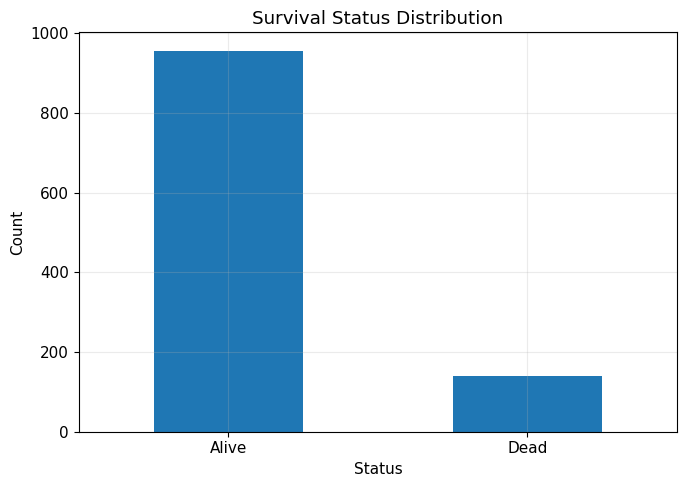

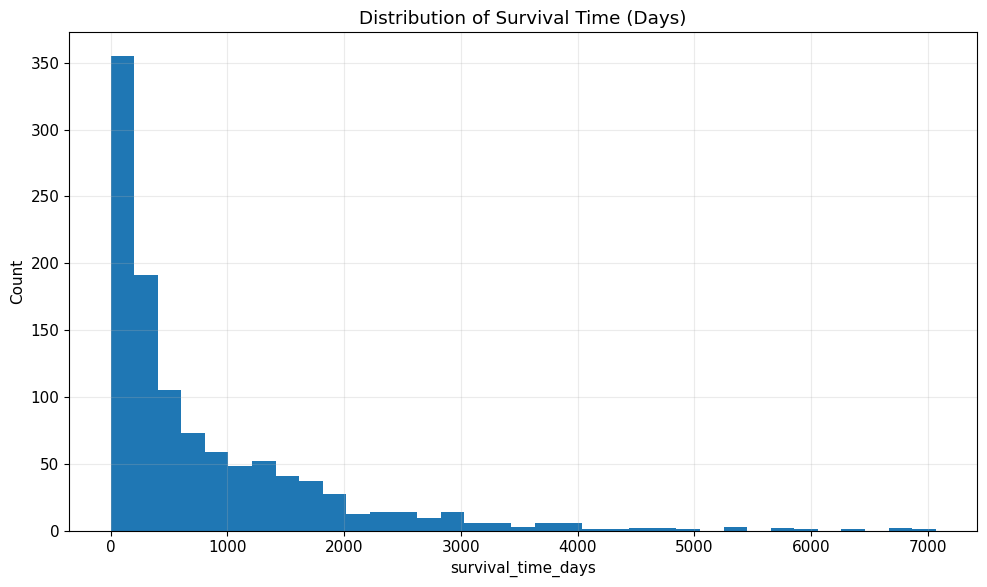

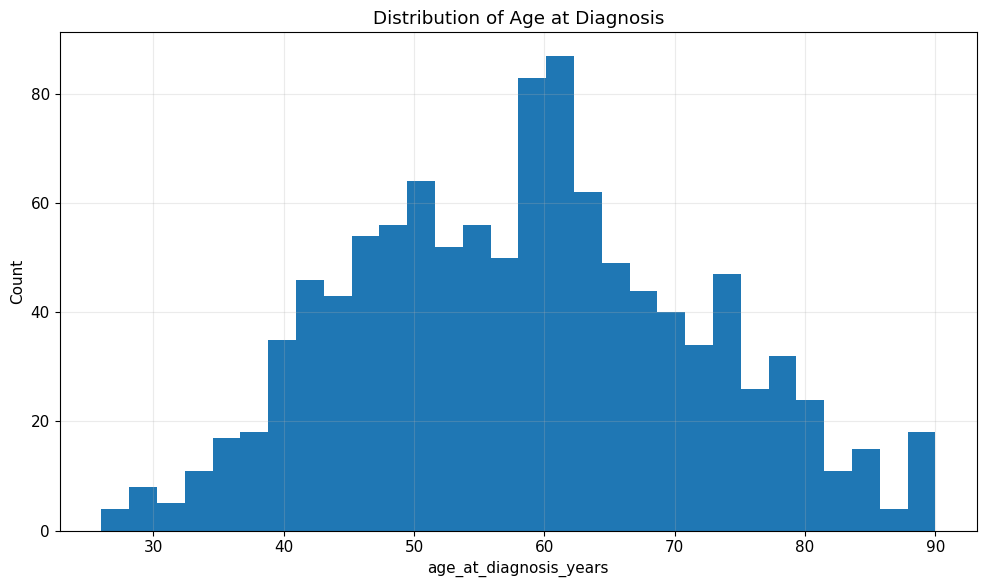

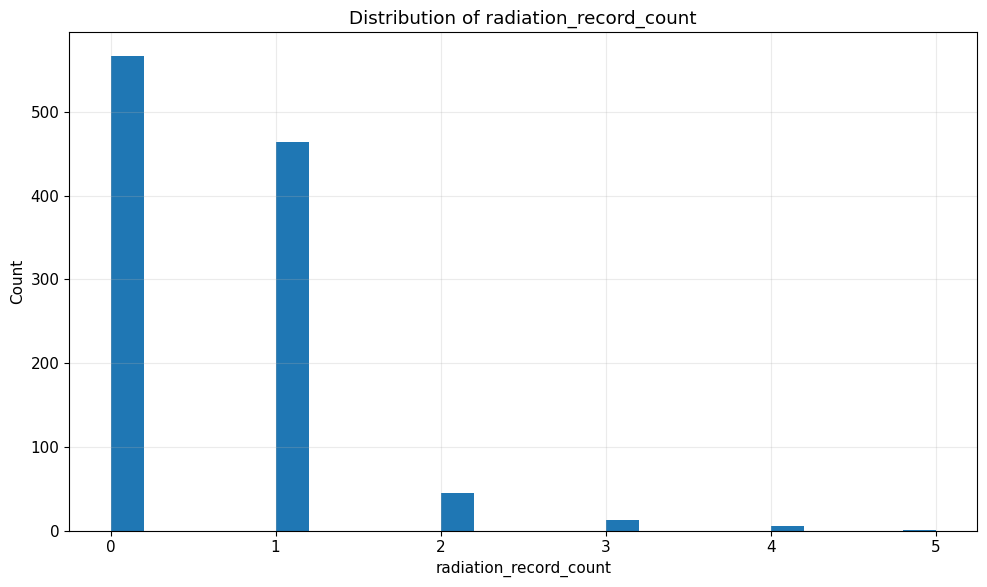

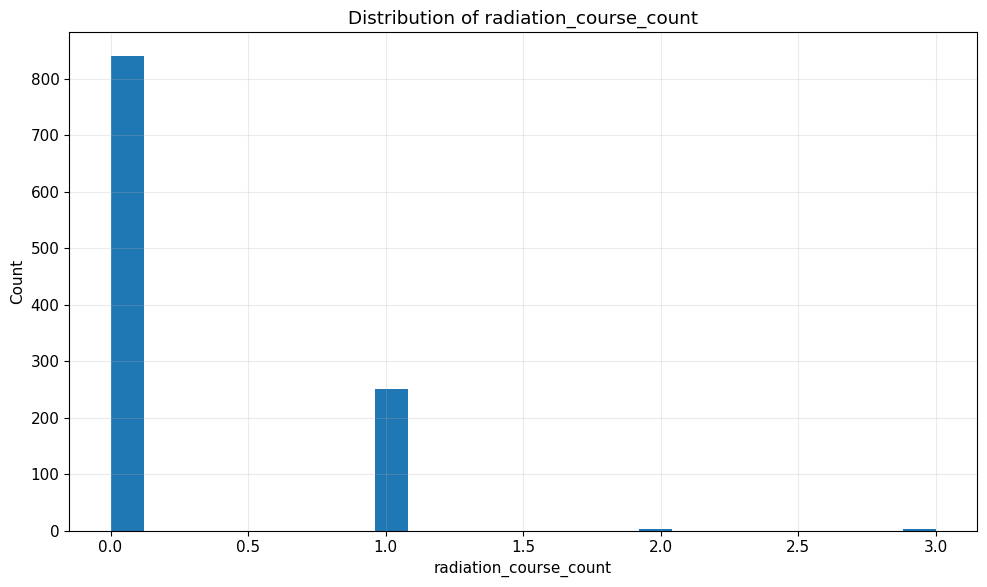

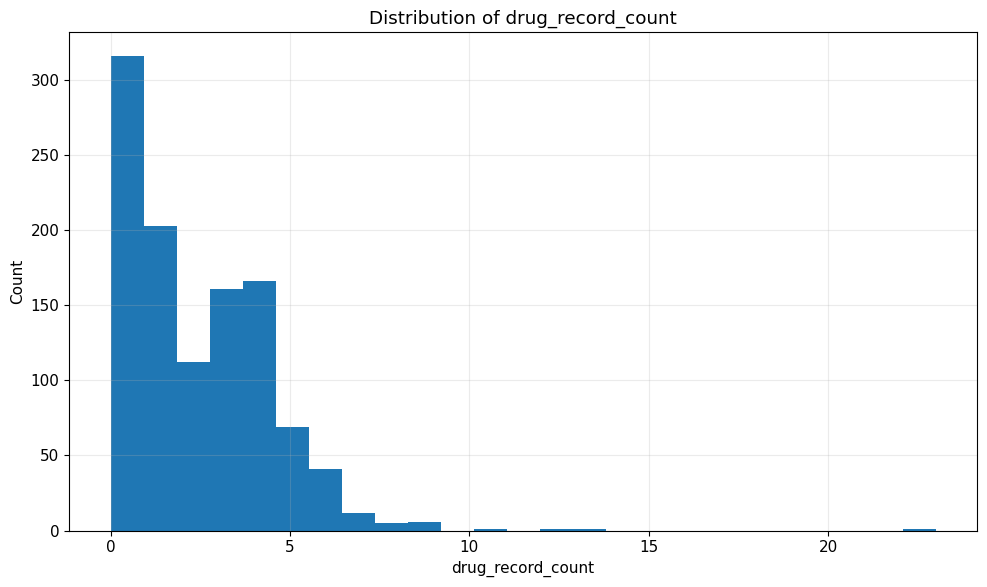

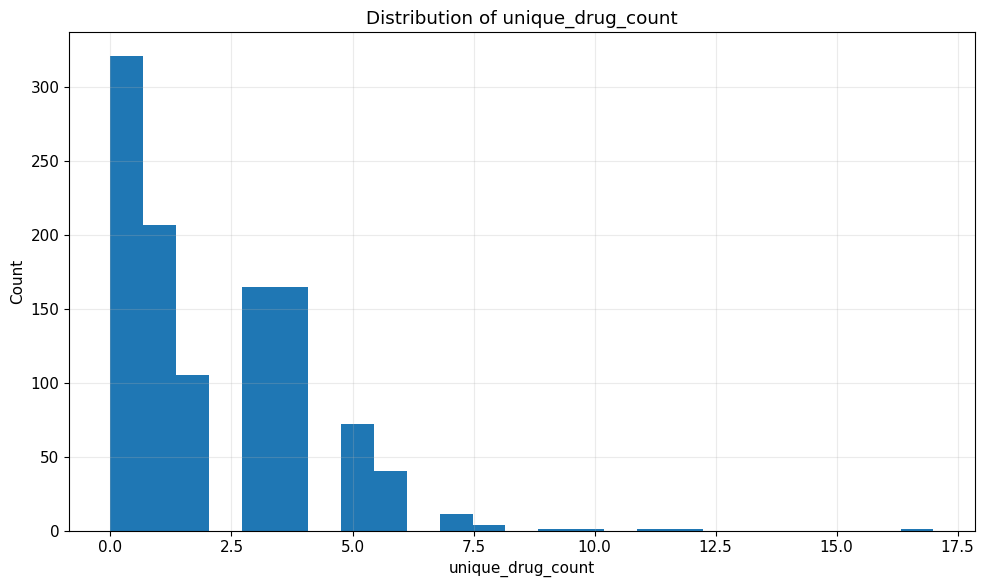

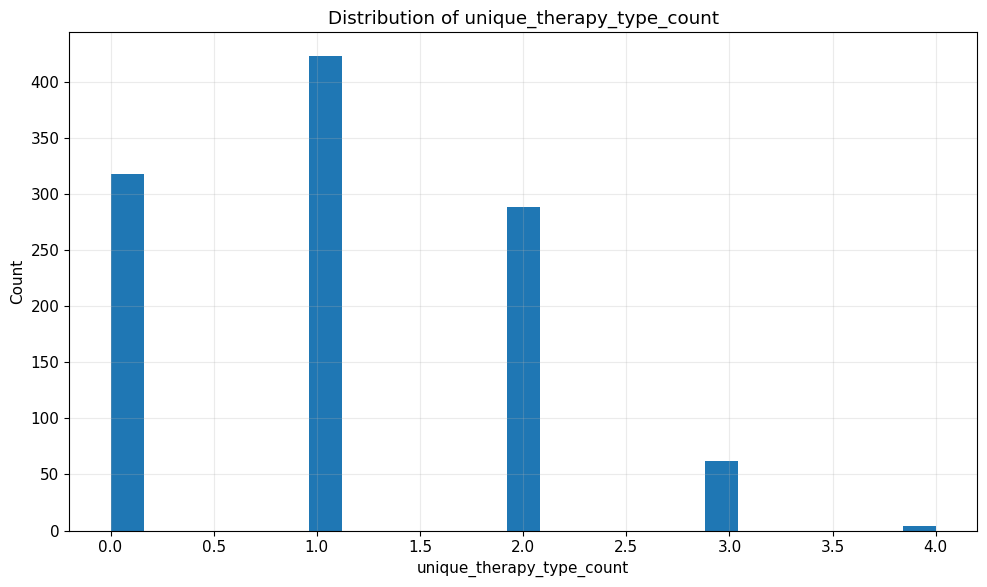

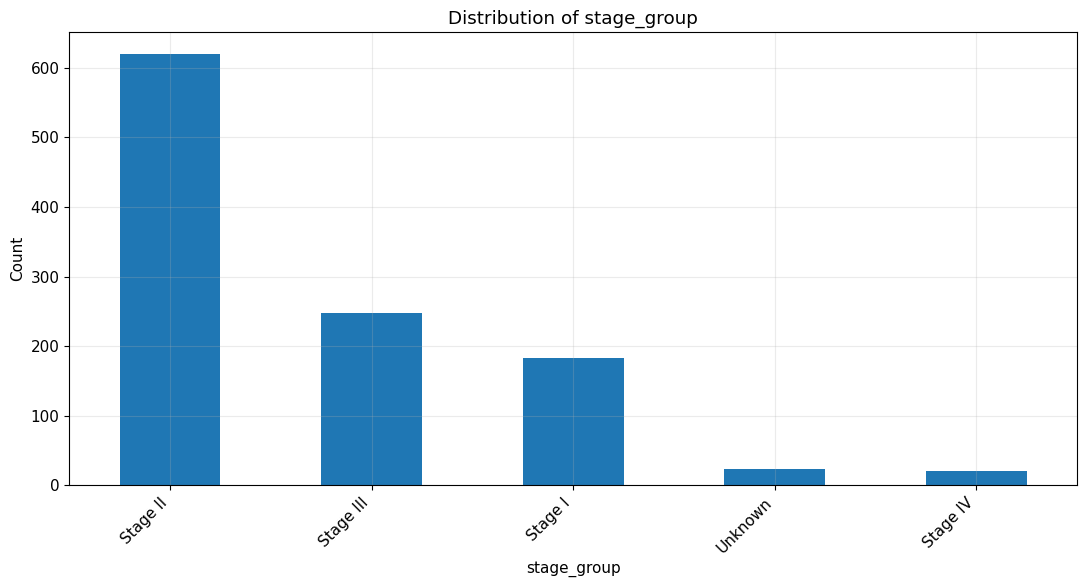

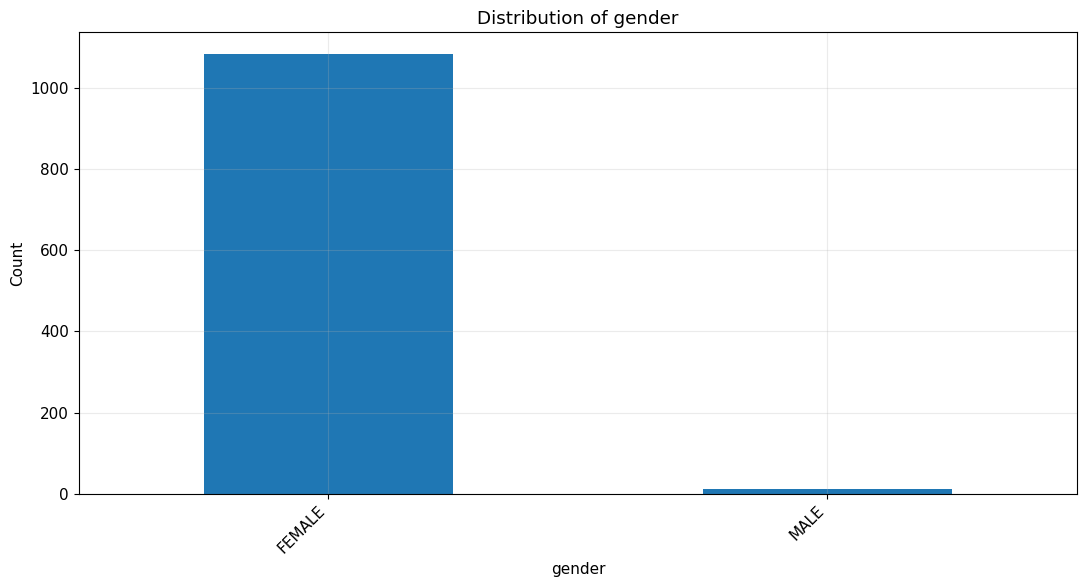

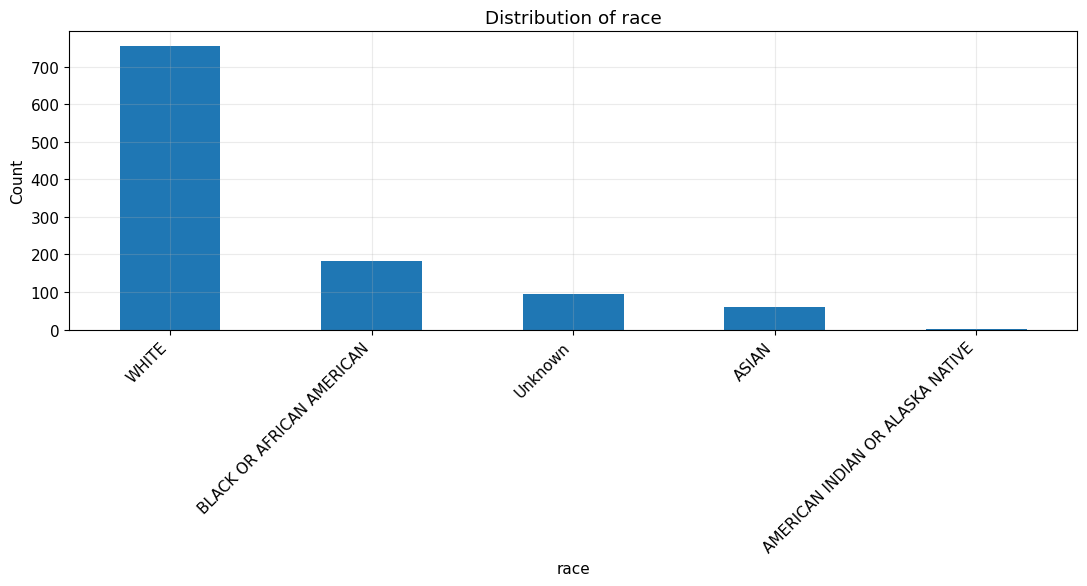

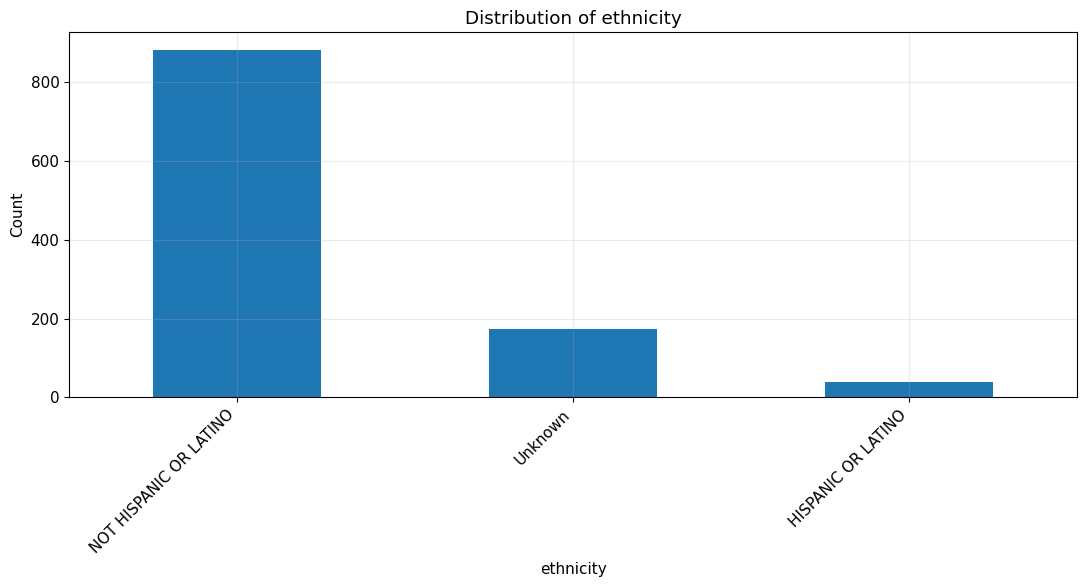

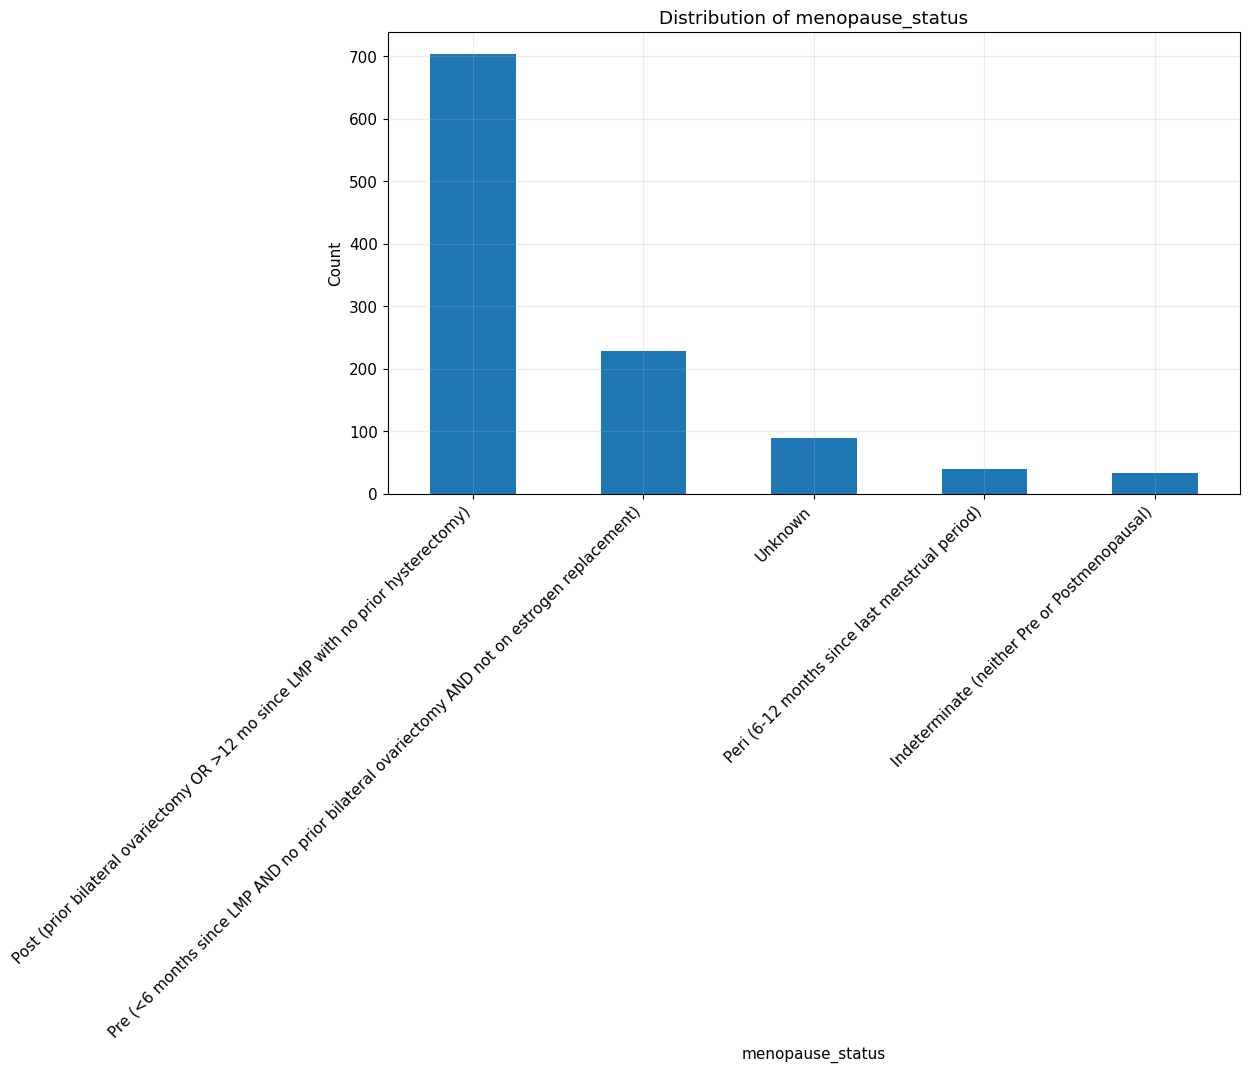

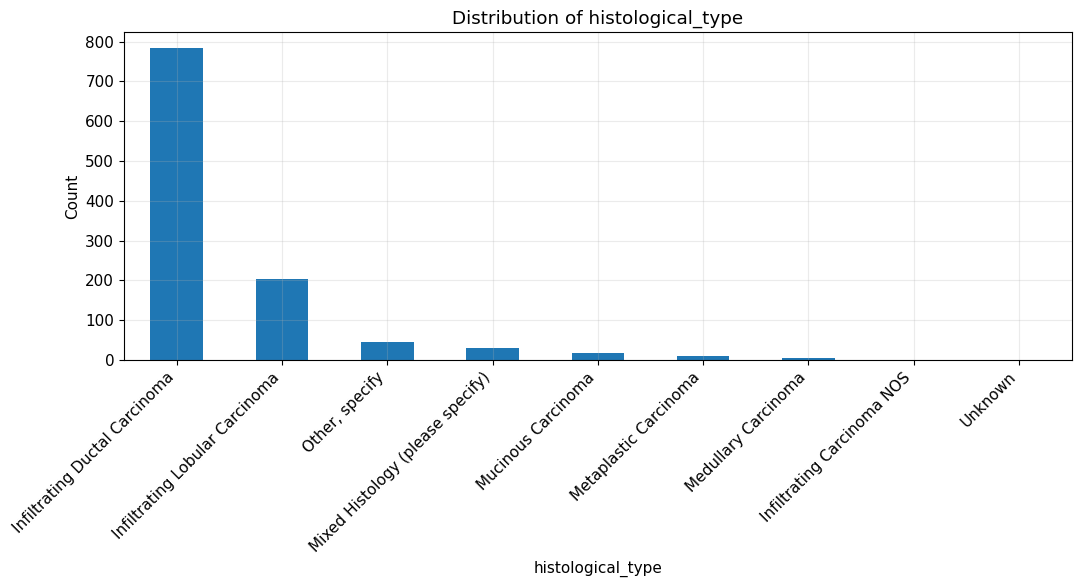

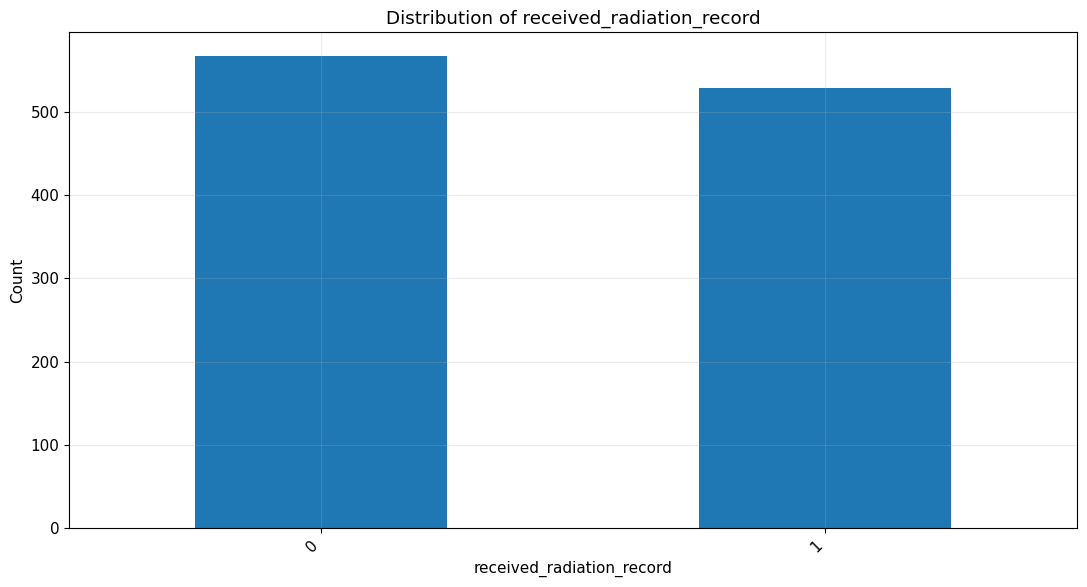

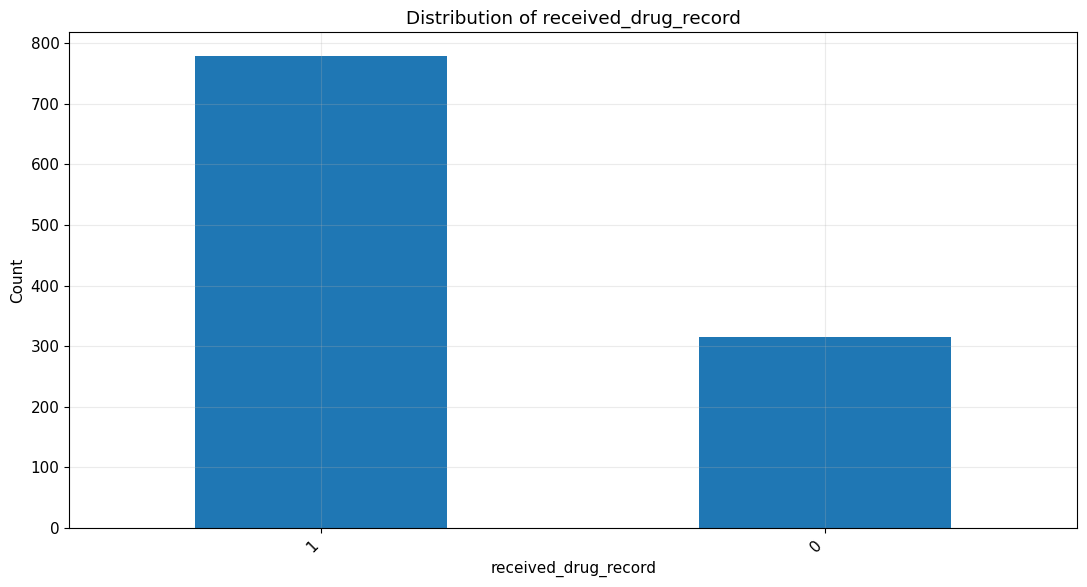

Finished plotting univariate distributions


In [21]:
# %% [4] Plotting univariate distributions

# Outcome distribution
plt.figure(figsize=(7, 5))
eda["event"].map({0: "Alive", 1: "Dead"}).value_counts().plot(kind="bar")
plt.title("Survival Status Distribution")
plt.xlabel("Status")
plt.ylabel("Count")
plt.xticks(rotation=0)
show_fig()

# Survival time distribution
plot_histogram(eda["survival_time_days"], "Distribution of Survival Time (Days)", bins=35)

# Age distribution
plot_histogram(eda["age_at_diagnosis_years"], "Distribution of Age at Diagnosis", bins=30)

# Treatment count distributions
for col in ["radiation_record_count", "radiation_course_count", "drug_record_count", "unique_drug_count", "unique_therapy_type_count"]:
    if col in eda.columns:
        plot_histogram(eda[col], f"Distribution of {col}", bins=25)

# Key categorical predictors
for col in ["stage_group", "gender", "race", "ethnicity", "menopause_status", "histological_type", "received_radiation_record", "received_drug_record"]:
    if col in eda.columns:
        plot_bar_counts(eda, col, f"Distribution of {col}")

print("Finished plotting univariate distributions")

**Outcome-based comparisons for numeric variables**

- This section compares continuous variables between alive and deceased patients.
- We use both Mann–Whitney U tests and Welch's t-tests to see whether the distributions differ by outcome status.

**The boxplots provide a visual version of the same comparison.**

,variable,alive_median,dead_median,mannwhitney_u,mannwhitney_p,ttest_stat,ttest_p
1,survival_time_days,360.0,1137.0,39238.0,2.740548e-15,-6.868075,1.322528e-10
6,unique_therapy_type_count,1.0,0.0,91186.0,2.091365e-13,6.419717,1.242299e-09
4,drug_record_count,2.0,0.0,89404.0,4.647383e-11,2.941841,3.753083e-03
5,unique_drug_count,2.0,0.0,89168.0,7.113274e-11,3.442076,7.341183e-04
2,radiation_record_count,1.0,0.0,82057.5,9.031510e-07,3.130453,2.051004e-03
3,radiation_course_count,0.0,0.0,79250.0,1.274775e-06,7.270978,3.326754e-12
0,age_at_diagnosis_years,58.0,61.0,60423.0,6.583004e-02,-1.888588,6.064948e-02


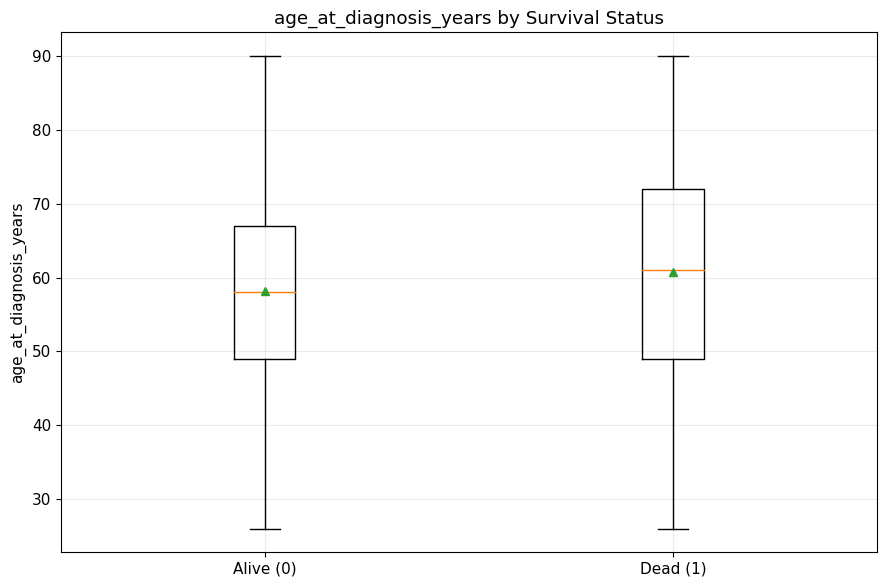

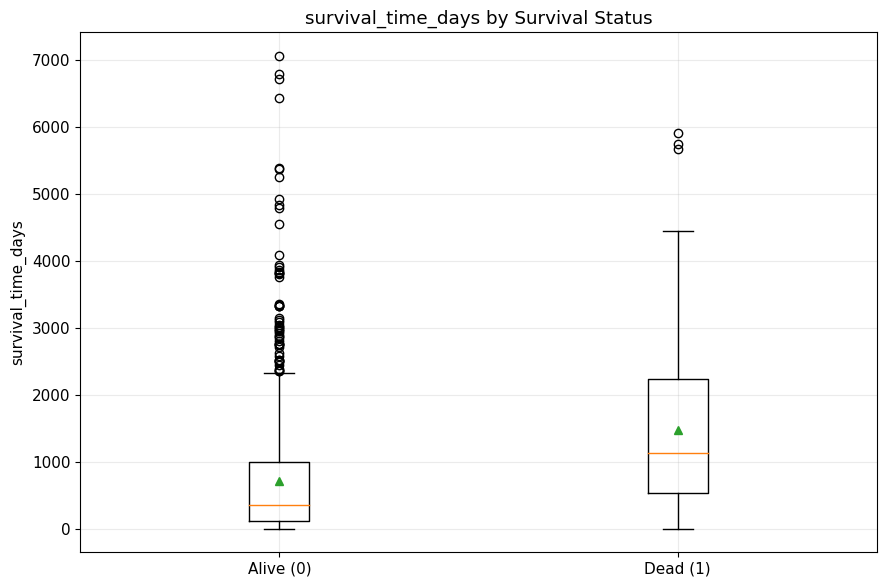

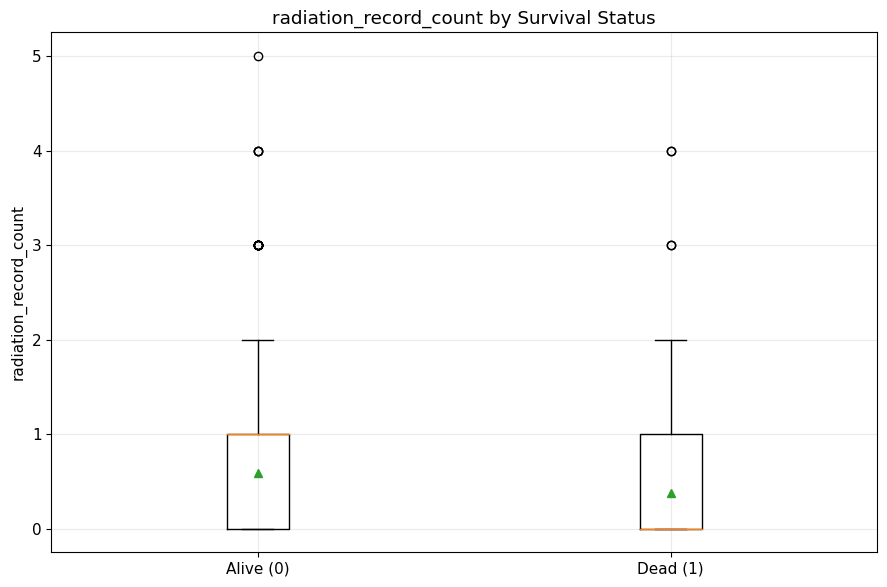

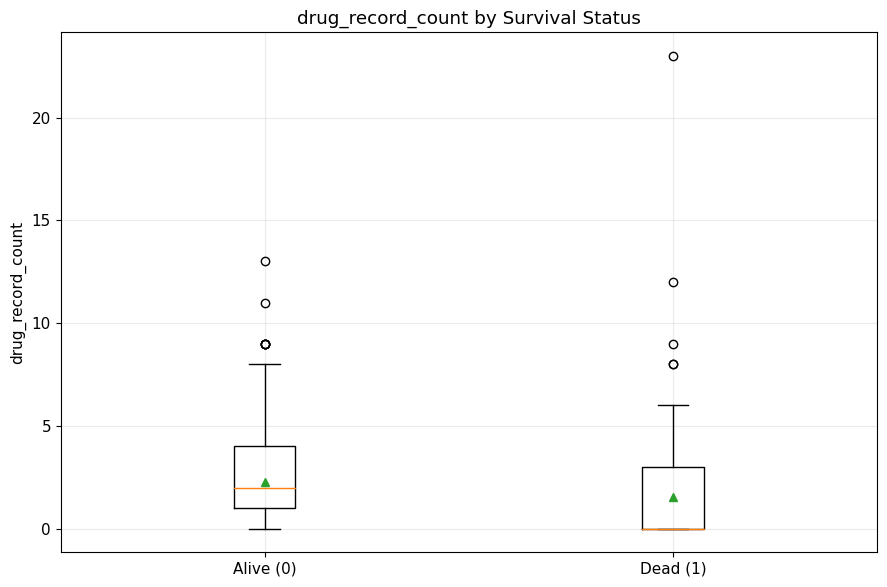

In [22]:
# %% [5] Comparing outcome groups with continuous variables
comparison_numeric_cols = [
    "age_at_diagnosis_years",
    "survival_time_days",
    "radiation_record_count",
    "radiation_course_count",
    "drug_record_count",
    "unique_drug_count",
    "unique_therapy_type_count"
]
comparison_numeric_cols = [c for c in comparison_numeric_cols if c in eda.columns]

rows = []
for col in comparison_numeric_cols:
    tmp = eda[[col, "event"]].dropna().copy()
    alive = pd.to_numeric(tmp.loc[tmp["event"] == 0, col], errors="coerce").dropna()
    dead = pd.to_numeric(tmp.loc[tmp["event"] == 1, col], errors="coerce").dropna()

    if len(alive) > 0 and len(dead) > 0:
        mw = stats.mannwhitneyu(alive, dead, alternative="two-sided")
        tt = stats.ttest_ind(alive, dead, equal_var=False, nan_policy="omit")
        rows.append({
            "variable": col,
            "alive_median": alive.median(),
            "dead_median": dead.median(),
            "mannwhitney_u": mw.statistic,
            "mannwhitney_p": mw.pvalue,
            "ttest_stat": tt.statistic,
            "ttest_p": tt.pvalue,
        })

num_group_tests = pd.DataFrame(rows).sort_values("mannwhitney_p")
show_table(num_group_tests)

for col in ["age_at_diagnosis_years", "survival_time_days", "radiation_record_count", "drug_record_count"]:
    if col in eda.columns:
        plot_box_by_event(eda, col, f"{col} by Survival Status")

**Outcome-based comparisons for categorical variables**

- This section evaluates whether categorical predictors are associated with survival outcome.
- Chi-square tests identify statistically significant associations, while Cramér's V gives a sense of effect size.
- We also calculate event rates within each category to make the results easier to interpret clinically.

In [23]:
# %% [6] Comparing outcome groups with categorical variables

cat_test_rows = []
for col in categorical_cols:
    if col not in eda.columns or col in ["received_radiation_record", "received_drug_record"]:
        continue

    tmp = eda[[col, "event"]].dropna().copy()
    contingency = pd.crosstab(tmp[col], tmp["event"])
    if contingency.shape[0] >= 2 and contingency.shape[1] == 2:
        chi2, p, dof, expected = stats.chi2_contingency(contingency)
        v = cramers_v(contingency)
        cat_test_rows.append({
            "variable": col,
            "chi2": chi2,
            "dof": dof,
            "p_value": p,
            "cramers_v": v,
            "levels": contingency.shape[0]
        })

cat_tests = pd.DataFrame(cat_test_rows).sort_values("p_value")
show_table(cat_tests)

# Event rates for the most clinically important categorical variables
for col in ["stage_group", "gender", "race", "ethnicity", "menopause_status", "histological_type", "er_status_by_ihc", "pr_status_by_ihc", "her2_status_by_ihc"]:
    if col in eda.columns:
        rate_table = binary_event_rate_table(eda, col)
        print(f"\nEvent rate by {col}:")
        show_table(rate_table)

,variable,chi2,dof,p_value,cramers_v,levels
4,stage_group,92.427240,4,4.015569e-19,0.290531,5
3,menopause_status,62.066460,4,1.066695e-12,0.238079,5
8,her2_status_by_ihc,59.517181,4,3.664163e-12,0.233139,5
6,er_status_by_ihc,19.672743,3,1.984206e-04,0.134037,4
2,ethnicity,14.063274,2,8.834844e-04,0.113328,3
1,race,9.170532,4,5.697550e-02,0.091515,5
7,pr_status_by_ihc,4.830260,3,1.846567e-01,0.066417,4
5,histological_type,7.237747,8,5.112125e-01,0.081301,9
0,gender,0.000886,1,9.762511e-01,0.000900,2



Event rate by stage_group:


,stage_group,n,event_rate
4,Stage IV,20,0.7000
5,Unknown,24,0.4583
3,Stage III,248,0.1573
2,Stage II,620,0.0984
1,Stage I,183,0.0820
0,Stage 0,0,NaN



Event rate by gender:


,gender,n,event_rate
0,FEMALE,1083,0.1283
1,MALE,12,0.0833


...

,er_status_by_ihc,n,event_rate
3,indeterminate,2,1.0000
0,No,238,0.1681
1,Unknown,48,0.1667
2,Yes,807,0.1115



Event rate by pr_status_by_ihc:


,pr_status_by_ihc,n,event_rate
3,indeterminate,4,0.2500
1,Unknown,49,0.1633
0,No,344,0.1541
2,Yes,698,0.1117



Event rate by her2_status_by_ihc:


,her2_status_by_ihc,n,event_rate
1,Unknown,177,0.2994
2,Yes,164,0.1341
0,No,563,0.0906
3,equivocal,179,0.0782
4,indeterminate,12,0.0000


**Informative missingness analysis**

- Missingness can sometimes carry information rather than being random.
- This section checks whether the engineered missingness indicators are associated with survival outcome.
- If they are, that supports keeping the missingness flags in later modeling.


In [24]:
# %% [7] Analyzing informative missingness

missing_indicator_cols = [c for c in eda.columns if c.endswith("_was_missing")]
missing_rows = []

for col in missing_indicator_cols:
    tmp = eda[[col, "event"]].dropna().copy()
    contingency = pd.crosstab(tmp[col], tmp["event"])
    if contingency.shape == (2, 2):
        chi2, p, dof, expected = stats.chi2_contingency(contingency)
        missing_rows.append({
            "missing_indicator": col,
            "event_rate_missing": tmp.loc[tmp[col] == 1, "event"].mean(),
            "event_rate_not_missing": tmp.loc[tmp[col] == 0, "event"].mean(),
            "chi2": chi2,
            "p_value": p
        })

missingness_tests = pd.DataFrame(missing_rows).sort_values("p_value")
show_table(missingness_tests)

,missing_indicator,event_rate_missing,event_rate_not_missing,chi2,p_value
7,her2_status_by_ihc_was_missing,0.299435,0.094771,53.921438,2.086685e-13
2,menopause_status_was_missing,0.292135,0.113320,21.870270,2.917186e-06
3,stage_group_was_missing,0.458333,0.120448,21.099103,4.361321e-06
1,ethnicity_was_missing,0.057471,0.141151,8.455214,3.639984e-03
0,race_was_missing,0.073684,0.133000,2.231351,1.352355e-01
5,er_status_by_ihc_was_missing,0.166667,0.126074,0.363014,5.468370e-01
6,pr_status_by_ihc_was_missing,0.163265,0.126195,0.292300,5.887501e-01
4,histological_type_was_missing,0.000000,0.127971,0.000000,1.000000e+00


**Categorical association analysis**

- Here we examine relationships among the categorical predictors themselves using Cramér's V.
- This helps us identify whether some variables may be redundant or closely related before modeling.
- The heatmap is especially useful for quickly spotting strong associations.


Cramér's V association matrix:


,gender,race,ethnicity,menopause_status,stage_group,histological_type,er_status_by_ihc,pr_status_by_ihc,her2_status_by_ihc,received_radiation_record,received_drug_record
gender,1.000,0.033,0.081,0.354,0.070,0.061,0.063,0.044,0.033,0.040,0.019
race,0.033,1.000,0.480,0.127,0.091,0.105,0.131,0.120,0.140,0.166,0.132
ethnicity,0.081,0.480,1.000,0.083,0.065,0.127,0.099,0.087,0.115,0.101,0.133
menopause_status,0.354,0.127,0.083,1.000,0.159,0.105,0.099,0.069,0.175,0.168,0.293
stage_group,0.070,0.091,0.065,0.159,1.000,0.092,0.099,0.047,0.086,0.141,0.109
histological_type,0.061,0.105,0.127,0.105,0.092,1.000,0.171,0.152,0.083,0.093,0.145
er_status_by_ihc,0.063,0.131,0.099,0.099,0.099,0.171,1.000,0.697,0.278,0.059,0.075
pr_status_by_ihc,0.044,0.120,0.087,0.069,0.047,0.152,0.697,1.000,0.275,0.044,0.082
her2_status_by_ihc,0.033,0.140,0.115,0.175,0.086,0.083,0.278,0.275,1.000,0.124,0.264
received_radiation_record,0.040,0.166,0.101,0.168,0.141,0.093,0.059,0.044,0.124,1.000,0.455


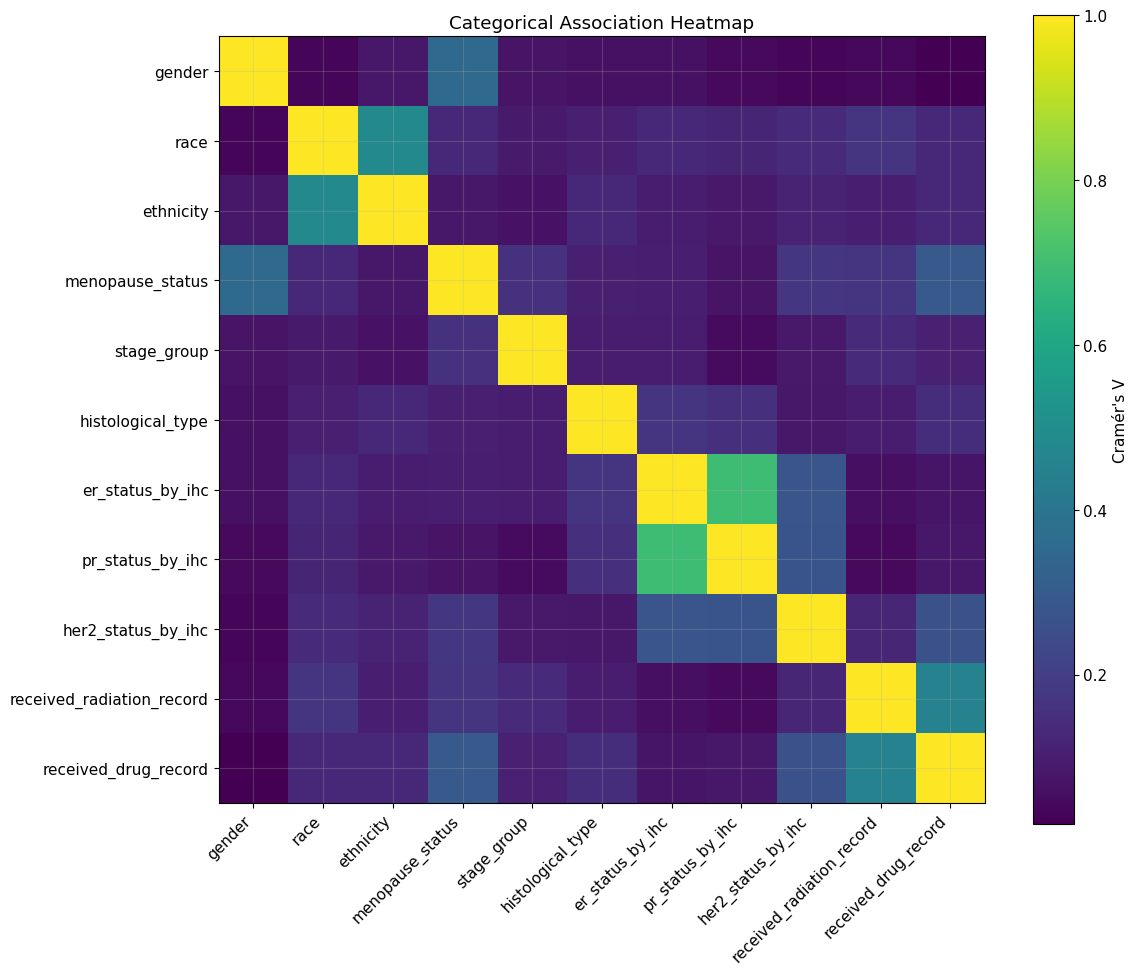

In [25]:
# %% [8] Building categorical association tables

assoc_targets = [
    "gender",
    "race",
    "ethnicity",
    "menopause_status",
    "stage_group",
    "histological_type",
    "er_status_by_ihc",
    "pr_status_by_ihc",
    "her2_status_by_ihc",
    "received_radiation_record",
    "received_drug_record"
]
assoc_targets = [c for c in assoc_targets if c in eda.columns]

assoc_matrix = pd.DataFrame(index=assoc_targets, columns=assoc_targets, dtype=float)

for i, col1 in enumerate(assoc_targets):
    for col2 in assoc_targets[i:]:
        if col1 == col2:
            assoc_matrix.loc[col1, col2] = 1.0
            continue

        tmp = eda[[col1, col2]].dropna().copy()

        # Convert both columns to strings to ensure crosstabs behave consistently.
        s1 = tmp[col1].astype("string")
        s2 = tmp[col2].astype("string")

        if s1.nunique() < 2 or s2.nunique() < 2:
            val = np.nan
        else:
            ct = pd.crosstab(s1, s2)
            val = cramers_v(ct)

        assoc_matrix.loc[col1, col2] = val
        assoc_matrix.loc[col2, col1] = val

print("\nCramér's V association matrix:")
show_table(assoc_matrix.round(3))

plt.figure(figsize=(12, 10))
plt.imshow(assoc_matrix.astype(float), cmap="viridis", interpolation="nearest")
plt.colorbar(label="Cramér's V")
plt.xticks(range(len(assoc_targets)), assoc_targets, rotation=45, ha="right")
plt.yticks(range(len(assoc_targets)), assoc_targets)
plt.title("Categorical Association Heatmap")
show_fig()

**Numeric correlation and multicollinearity**

- This final EDA section checks whether numeric variables are highly correlated with each other.
- We use Spearman correlation because several predictors are skewed or count-based.
- We also calculate VIF to identify multicollinearity that could affect regression-based modeling.


Spearman correlation matrix:


,variable,age_at_diagnosis_years,survival_time_days,radiation_record_count,radiation_course_count,drug_record_count,unique_drug_count,unique_therapy_type_count
0,age_at_diagnosis_years,1.000,-0.136,-0.100,-0.062,-0.283,-0.284,-0.211
1,survival_time_days,-0.136,1.000,0.101,0.179,0.185,0.184,0.149
2,radiation_record_count,-0.100,0.101,1.000,0.534,0.465,0.458,0.461
3,radiation_course_count,-0.062,0.179,0.534,1.000,0.378,0.375,0.359
4,drug_record_count,-0.283,0.185,0.465,0.378,1.000,0.996,0.914
5,unique_drug_count,-0.284,0.184,0.458,0.375,0.996,1.000,0.910
6,unique_therapy_type_count,-0.211,0.149,0.461,0.359,0.914,0.910,1.000


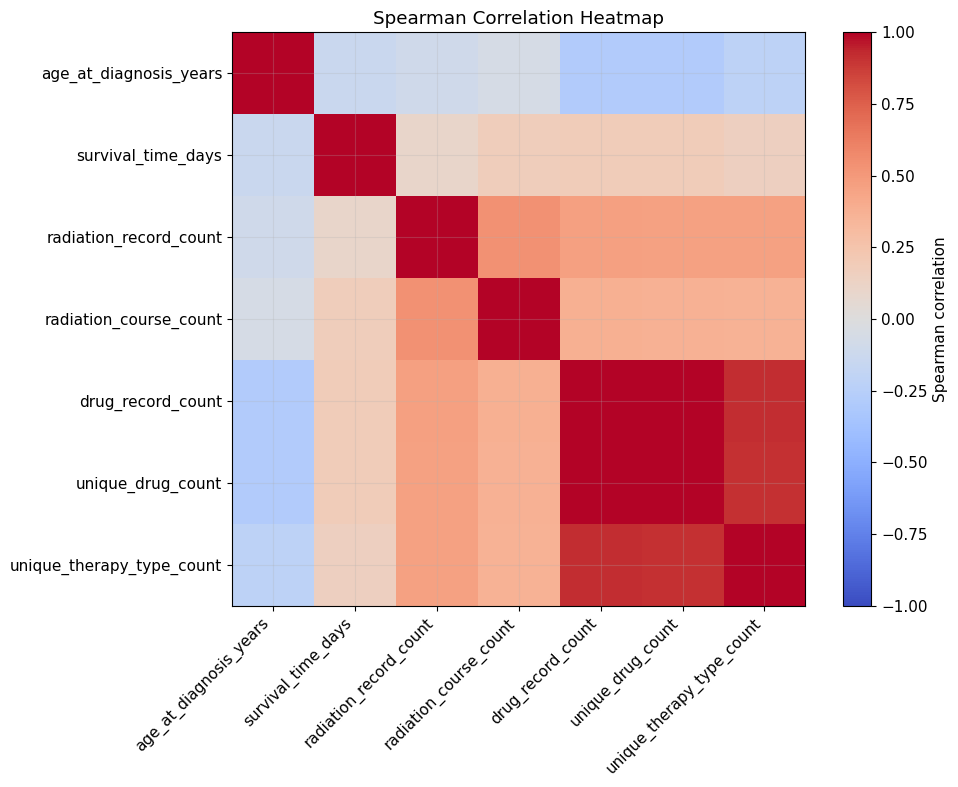


Variance Inflation Factors:


,variable,VIF
4,unique_drug_count,99.337118
3,drug_record_count,87.149278
5,unique_therapy_type_count,9.551797
1,radiation_record_count,2.351739
0,age_at_diagnosis_years,2.216125
2,radiation_course_count,1.679868


In [26]:
# %% [9] Analyzing numeric relationships and multicollinearity
corr_cols = [
    "age_at_diagnosis_years",
    "survival_time_days",
    "radiation_record_count",
    "radiation_course_count",
    "drug_record_count",
    "unique_drug_count",
    "unique_therapy_type_count"
]
corr_cols = [c for c in corr_cols if c in eda.columns]

corr_df = eda[corr_cols].copy()
spearman_corr = corr_df.corr(method="spearman")

print("\nSpearman correlation matrix:")
show_table(spearman_corr.round(3).reset_index().rename(columns={"index": "variable"}))

plt.figure(figsize=(10, 8))
plt.imshow(spearman_corr.values, cmap="coolwarm", vmin=-1, vmax=1, interpolation="nearest")
plt.colorbar(label="Spearman correlation")
plt.xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
plt.yticks(range(len(corr_cols)), corr_cols)
plt.title("Spearman Correlation Heatmap")
show_fig()

# Calculate VIF on the core numeric predictors.
if HAS_VIF:
    vif_cols = [
        "age_at_diagnosis_years",
        "radiation_record_count",
        "radiation_course_count",
        "drug_record_count",
        "unique_drug_count",
        "unique_therapy_type_count"
    ]
    vif_cols = [c for c in vif_cols if c in eda.columns]

    vif_frame = eda[vif_cols].copy().dropna()
    if len(vif_frame) > 0 and len(vif_cols) > 1:
        vif_results = pd.DataFrame({
            "variable": vif_frame.columns,
            "VIF": [variance_inflation_factor(vif_frame.values, i) for i in range(vif_frame.shape[1])]
        }).sort_values("VIF", ascending=False)
        print("\nVariance Inflation Factors:")
        show_table(vif_results)
    else:
        print("\nSkipping VIF because the numeric matrix is too small.")
else:
    print("\nSkipping VIF because statsmodels is not available.")

**EDA summary**

This part of the notebook has now covered the main exploratory steps:
 - dataset overview
 - descriptive statistics
 - univariate distributions
 - group comparisons by survival outcome
 - informative missingness
 - categorical association structure
 - numeric correlation and multicollinearity

**These results provide the foundation for the next phase of the project, where we will move into survival modeling.**